### Import libraries

In [1]:
import os
import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import random
import pickle
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)

batch_time=500
niters=5000
test_freq=50

activations = {
    'relu':    nn.ReLU(),
    'sigmoid': nn.Sigmoid(),
    'elu':     nn.ELU(),
    'tanh':    nn.Tanh(),
    'gelu':    nn.GELU(),
    'leaky_relu': nn.LeakyReLU()
}

device = torch.device('cuda:' + str(gpu) if torch.cuda.is_available() else 'cpu')

from misc import preprocessing
_ = preprocessing()

### Import data

In [2]:
file = './data_1D_hypo_500real'
with open(file, 'rb') as f_obj:
    data = pickle.load(f_obj)
    
stress_t,stress_tdt,pl_strain_t,pl_strain_tdt,el_strain_t,el_strain_tdt,strain_t,strain_tdt,energy_t,energy_tdt,dissipation_rate_tdt = data

stress_t = np.expand_dims(stress_t,1)
stress_tdt = np.expand_dims(stress_tdt,1)
pl_strain_t = np.expand_dims(pl_strain_t,1)
pl_strain_tdt = np.expand_dims(pl_strain_tdt,1)
el_strain_t = np.expand_dims(el_strain_t,1)
el_strain_tdt = np.expand_dims(el_strain_tdt,1)
strain_t = np.expand_dims(strain_t,1)
strain_tdt = np.expand_dims(strain_tdt,1)
energy_t = np.expand_dims(energy_t,1)
energy_tdt = np.expand_dims(energy_tdt,1)
dissipation_rate_tdt = np.expand_dims(dissipation_rate_tdt,1)

dstress = stress_tdt - stress_t
dstrain = strain_tdt - strain_t
dstrain_pl = pl_strain_tdt - pl_strain_t
dstrain_el = el_strain_tdt - el_strain_t

#### Split data in paths (batch_time step for each path)

In [3]:
strain_t = np.reshape(strain_t,(-1,batch_time,1),order='C')[:,:,:,None]
strain_tdt = np.reshape(strain_tdt,(-1,batch_time,1),order='C')[:,:,:,None]
dstrain = np.reshape(dstrain,(-1,batch_time,1),order='C')[:,:,:,None]

pl_strain_t = np.reshape(pl_strain_t,(-1,batch_time,1),order='C')[:,:,:,None]
pl_strain_tdt = np.reshape(pl_strain_tdt,(-1,batch_time,1),order='C')[:,:,:,None]
dstrain_pl = np.reshape(dstrain_pl,(-1,batch_time,1),order='C')[:,:,:,None]

el_strain_t = np.reshape(el_strain_t,(-1,batch_time,1),order='C')[:,:,:,None]
el_strain_tdt = np.reshape(el_strain_tdt,(-1,batch_time,1),order='C')[:,:,:,None]
dstrain_el = np.reshape(dstrain_el,(-1,batch_time,1),order='C')[:,:,:,None]

stress_t = np.reshape(stress_t,(-1,batch_time,1),order='C')[:,:,:,None]
stress_tdt = np.reshape(stress_tdt,(-1,batch_time,1),order='C')[:,:,:,None]
dstress = np.reshape(dstress,(-1,batch_time,1),order='C')[:,:,:,None]

energy_t = np.reshape(energy_t,(-1,batch_time,1),order='C')[:,:,:,None]
energy_tdt = np.reshape(energy_tdt,(-1,batch_time,1),order='C')[:,:,:,None]
dissipation_rate_tdt = np.reshape(dissipation_rate_tdt,(-1,batch_time,1),order='C')[:,:,:,None]

data_size = strain_t.shape[0]

#### Split into training, validation, and test sets

In [4]:
train_percentage = .1

ntrain = int(round(data_size * train_percentage))
nval = int(round(data_size * 0.5 *(1.- train_percentage)))
ntest = nval

print("Number of samples: ", data_size)
print("Training samples : ", ntrain)
print("Validation samples : ", nval)
print("Test samples : ", ntest)
print("Total : ", ntest + nval + ntrain)

Number of samples:  20
Training samples :  2
Validation samples :  9
Test samples :  9
Total :  20


In [5]:
strain_t_tv,strain_t_test = _.slice_data(strain_t,ntrain,nval)
strain_tdt_tv,strain_tdt_test = _.slice_data(strain_tdt,ntrain,nval)
pl_strain_t_tv,pl_strain_t_test = _.slice_data(pl_strain_t,ntrain,nval)
pl_strain_tdt_tv,pl_strain_tdt_test = _.slice_data(pl_strain_tdt,ntrain,nval)
dstrain_tv,dstrain_test = _.slice_data(dstrain,ntrain,nval)
dstrain_pl_tv,dstrain_pl_test = _.slice_data(dstrain_pl,ntrain,nval)

stress_t_tv,stress_t_test = _.slice_data(stress_t,ntrain,nval)
stress_tdt_tv,stress_tdt_test = _.slice_data(stress_tdt,ntrain,nval)
dstress_tv,dstress_test = _.slice_data(dstress,ntrain,nval)

energy_t_tv,energy_t_test = _.slice_data(energy_t,ntrain,nval)
energy_tdt_tv,energy_tdt_test = _.slice_data(energy_tdt,ntrain,nval)
dissipation_rate_tdt_tv,dissipation_rate_tdt_test = _.slice_data(dissipation_rate_tdt,ntrain,nval)

#### Compute statistics of the data (for normalization)

In [6]:
prm_e = _.GetParams(strain_tdt_tv)
prm_de = _.GetParams(dstrain_tv)

prm_s = _.GetParams(stress_tdt_tv)
prm_ds = _.GetParams(dstress_tv)

prm_z = _.GetParams(pl_strain_tdt_tv)
prm_dz = _.GetParams(dstrain_pl_tv)

prm_f = _.GetParams(energy_tdt_tv)
prm_d = _.GetParams(dissipation_rate_tdt_tv)

### TANN 

In [7]:
class TANN(nn.Module):

    def __init__(self,params_z,params_f,dtype=torch.float32):
        super(TANN, self).__init__()
        
        self.dtype = dtype
        i_NNz,o_NNz,h_NNz,act_NNz = params_z
        i_NNf,o_NNf,h_NNf,act_NNf = params_f
        
        
        self.NNz = self.constructor(i_NNz,
                                    o_NNz,
                                    h_NNz,
                                    act_NNz)
        
        self.NNf = self.constructor(i_NNf,
                                    o_NNf,
                                    h_NNf,
                                    act_NNf)
        
    def constructor(self, i_dim, o_dim, h_dim, act):
        dim = i_dim
        layers = torch.nn.Sequential()
        for hdim in h_dim:
            layers.append(nn.Linear(dim, hdim, dtype=self.dtype))
            layers.append(activations[act])
            dim = hdim
        layers.append(nn.Linear(dim, o_dim, dtype=self.dtype))
        return layers
    
    def Normalize(self,inputs,prm):
        '''
        Normalize features
        :inputs : data
        :prm : normalization parameters
        '''
        return torch.divide(torch.add(inputs, -prm[1]), prm[0])
    
    def DeNormalize(self,outputs,prm):
        '''
        Denormalize features
        :output : dimensionless data
        :prm : normalization parameters
        '''
        return torch.add(torch.multiply(outputs, prm[0]), prm[1])
    
    def forward(self,inp):
        inp = torch.autograd.Variable(inp,requires_grad=True)
        n_strain_t, n_pl_strain_t, n_dstrain = inp[:,0,None],inp[:,1,None],inp[:,2,None]
        
        # Normalize
        strain_t = self.DeNormalize(n_strain_t,prm_e)
        pl_strain_t = self.DeNormalize(n_pl_strain_t,prm_z)
        dstrain = self.DeNormalize(n_dstrain,prm_de)
        strain_tdt = strain_t+dstrain
        N_strain_tdt = self.Normalize(strain_tdt,prm_e)
        
        
        # Predict evolution law
        npl_dstrain = self.NNz(torch.cat((n_strain_t,n_pl_strain_t,n_dstrain),1))
        pl_dstrain = self.DeNormalize(npl_dstrain,prm_dz)
        pl_strain_tdt = pl_dstrain+pl_strain_t
        n_pl_strain_tdt = self.Normalize(pl_strain_tdt,prm_z)
        
        
        # Predict energy, stress, and dissipation rate
        n_energy_tdt = self.NNf(torch.cat((n_pl_strain_tdt,N_strain_tdt),1))
        energy_tdt = self.DeNormalize(n_energy_tdt,prm_f)
        
        
        
        # Stress
        stress_tdt = torch.autograd.grad(energy_tdt,strain_tdt,
                                     grad_outputs=torch.ones_like(strain_tdt),
                                     retain_graph=True,
                                     create_graph=True)[0]
        n_stress_tdt = self.Normalize(stress_tdt,prm_s)
        
        # Dissipation rate
        thermo_stress = -torch.autograd.grad(energy_tdt,pl_strain_tdt,
                                     grad_outputs=torch.ones_like(pl_strain_tdt),
                                     retain_graph=True,
                                     create_graph=True)[0]
        dissipation_tdt = thermo_stress*pl_dstrain
        n_dissipation_tdt = self.Normalize(dissipation_tdt,prm_d)
        
        return torch.cat((npl_dstrain,n_energy_tdt,n_stress_tdt,n_dissipation_tdt),1)

In [8]:
dtype=torch.float64
NNf_params = [3,1,[32,32,32],'relu']
NNu_params = [2,1,[144,144],'gelu']
TANNnet = TANN(NNf_params,NNu_params,dtype).to(device)
TANNnet.to(torch.double)

TANN(
  (NNz): Sequential(
    (0): Linear(in_features=3, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=32, bias=True)
    (5): ReLU()
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
  (NNf): Sequential(
    (0): Linear(in_features=2, out_features=144, bias=True)
    (1): GELU(approximate='none')
    (2): Linear(in_features=144, out_features=144, bias=True)
    (3): GELU(approximate='none')
    (4): Linear(in_features=144, out_features=1, bias=True)
  )
)

### Normalize datasets and assemble inputs and outputs

In [9]:
strain_t_tv = TANNnet.Normalize(torch.tensor(strain_t_tv),prm_e)
strain_tdt_tv = TANNnet.Normalize(torch.tensor(strain_tdt_tv),prm_e)
pl_strain_t_tv = TANNnet.Normalize(torch.tensor(pl_strain_t_tv),prm_z)
pl_strain_tdt_tv = TANNnet.Normalize(torch.tensor(pl_strain_tdt_tv),prm_z)
stress_tdt_tv = TANNnet.Normalize(torch.tensor(stress_tdt_tv),prm_s)

energy_tdt_tv = TANNnet.Normalize(torch.tensor(energy_tdt_tv),prm_f)
dissipation_rate_tdt_tv = TANNnet.Normalize(torch.tensor(dissipation_rate_tdt_tv),prm_d)

dstrain_tv = TANNnet.Normalize(torch.tensor(dstrain_tv),prm_de)
dstrain_pl_tv = TANNnet.Normalize(torch.tensor(dstrain_pl_tv),prm_dz)
dstress_tv = TANNnet.Normalize(torch.tensor(dstress_tv),prm_ds)

strain_t_test = TANNnet.Normalize(torch.tensor(strain_t_test),prm_e)
strain_tdt_test = TANNnet.Normalize(torch.tensor(strain_tdt_test),prm_e)
pl_strain_t_test = TANNnet.Normalize(torch.tensor(pl_strain_t_test),prm_z)
pl_strain_tdt_test = TANNnet.Normalize(torch.tensor(pl_strain_tdt_test),prm_z)
stress_tdt_test = TANNnet.Normalize(torch.tensor(stress_tdt_test),prm_s)

energy_tdt_test = TANNnet.Normalize(torch.tensor(energy_tdt_test),prm_f)
dissipation_rate_tdt_test = TANNnet.Normalize(torch.tensor(dissipation_rate_tdt_test),prm_d)

dstrain_test = TANNnet.Normalize(torch.tensor(dstrain_test),prm_de)
dstrain_pl_test = TANNnet.Normalize(torch.tensor(dstrain_pl_test),prm_dz)
dstress_test = TANNnet.Normalize(torch.tensor(dstress_test),prm_ds)


In [10]:
input_tv = torch.cat((strain_t_tv,pl_strain_t_tv,dstrain_tv),-1).to(device)
output_tv = torch.cat((dstrain_pl_tv,energy_tdt_tv,stress_tdt_tv,dissipation_rate_tdt_tv),-1).to(device)

input_test = torch.cat((strain_t_test,pl_strain_t_test,dstrain_test),-1).to(device)
output_test = torch.cat((dstrain_pl_test,energy_tdt_test,stress_tdt_test,dissipation_rate_tdt_test),-1).to(device)

### Training 

1  --  8.9692335
2  --  8.941515
3  --  8.918452
4  --  8.895409
5  --  8.872206
6  --  8.849089
7  --  8.826324
8  --  8.804121


9  --  8.78264
10  --  8.762
11  --  8.742287
12  --  8.723549
13  --  8.705819
14  --  8.689102
15  --  8.673388
16  --  8.658639
17  --  8.644824
18  --  8.631897


19  --  8.61981
20  --  8.608503
21  --  8.597919
22  --  8.588007
23  --  8.578714
24  --  8.57
25  --  8.561819
26  --  8.554111
27  --  8.546817
28  --  8.539902


29  --  8.533306
30  --  8.526984
31  --  8.520902
32  --  8.5150175
33  --  8.509296
34  --  8.503716
35  --  8.498247
36  --  8.492863
37  --  8.487541
38  --  8.482266
39  --  8.477016


40  --  8.471766
41  --  8.466512
42  --  8.461242
43  --  8.455956
44  --  8.450664
45  --  8.445354
46  --  8.440017
47  --  8.434637
48  --  8.429202
49  --  8.423713


50  --  8.418173


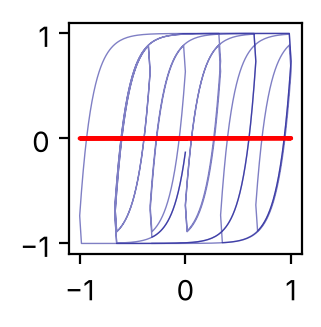

51  --  8.412581
52  --  8.406931
53  --  8.401227
54  --  8.39547
55  --  8.389662


56  --  8.383789
57  --  8.377851
58  --  8.371845
59  --  8.365769


60  --  8.359622
61  --  8.353382
62  --  8.347047
63  --  8.340656
64  --  8.334216
65  --  8.327706
66  --  8.32108


67  --  8.314279
68  --  8.3073635
69  --  8.300342
70  --  8.293238
71  --  8.286064


72  --  8.278837
73  --  8.271557
74  --  8.264213
75  --  8.256803
76  --  8.249345
77  --  8.24184
78  --  8.234288


79  --  8.226677
80  --  8.219021
81  --  8.211338
82  --  8.203632
83  --  8.195894


84  --  8.188113
85  --  8.180289
86  --  8.1724205
87  --  8.164516
88  --  8.156594
89  --  8.148689


90  --  8.140805
91  --  8.132924
92  --  8.12504
93  --  8.117149
94  --  8.109251
95  --  8.10134


96  --  8.093413
97  --  8.085469
98  --  8.077512
99  --  8.069569
100  --  8.061656


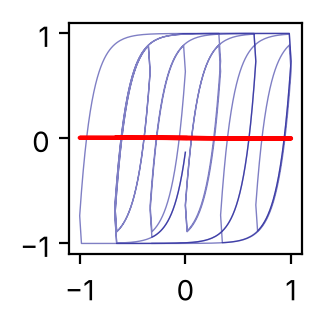

101  --  8.053749
102  --  8.04584
103  --  8.037936
104  --  8.03004


105  --  8.02215
106  --  8.014272
107  --  8.006408
108  --  7.998577
109  --  7.990784
110  --  7.9830146
111  --  7.975264
112  --  7.9675264


113  --  7.959802
114  --  7.9520893
115  --  7.944394
116  --  7.936722


117  --  7.929067
118  --  7.921438
119  --  7.91385
120  --  7.9063187
121  --  7.8988347
122  --  7.8913956
123  --  7.883995
124  --  7.876645


125  --  7.8693433
126  --  7.862091
127  --  7.85489
128  --  7.8477545


129  --  7.8406825
130  --  7.8336887
131  --  7.826774
132  --  7.8199296
133  --  7.81315
134  --  7.806436
135  --  7.799785
136  --  7.793196


137  --  7.786673
138  --  7.780217
139  --  7.773829
140  --  7.767509


141  --  7.7612557
142  --  7.7550716
143  --  7.7489543
144  --  7.742906
145  --  7.736923
146  --  7.7310143
147  --  7.725183
148  --  7.7194376


149  --  7.71377
150  --  7.7081804


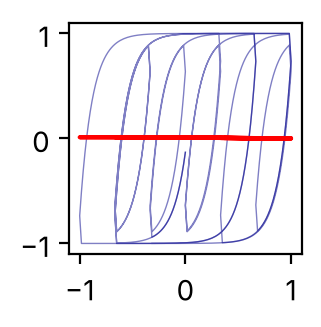

151  --  7.7026725
152  --  7.6972427
153  --  7.691886
154  --  7.686603
155  --  7.6813936
156  --  7.6762576
157  --  7.671194
158  --  7.666204


159  --  7.661286
160  --  7.656442
161  --  7.651671
162  --  7.646973


163  --  7.6423507
164  --  7.637803
165  --  7.633331
166  --  7.628929
167  --  7.624599
168  --  7.6203394
169  --  7.616151
170  --  7.6120367


171  --  7.6080008
172  --  7.6040454
173  --  7.600171
174  --  7.596372


175  --  7.592645
176  --  7.588991
177  --  7.5854053
178  --  7.5818872
179  --  7.5784388
180  --  7.575059
181  --  7.5717483
182  --  7.568507


183  --  7.565335
184  --  7.562232
185  --  7.5592
186  --  7.556238


187  --  7.5533504
188  --  7.550536
189  --  7.5477924
190  --  7.5451193
191  --  7.542511
192  --  7.539965
193  --  7.5374813


194  --  7.5350566
195  --  7.532691
196  --  7.5303817


197  --  7.528127
198  --  7.525928
199  --  7.5237794
200  --  7.521679


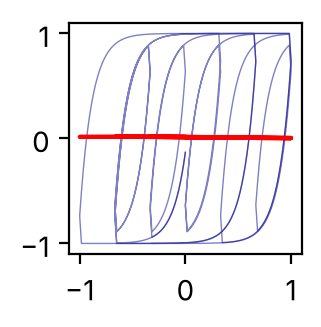

201  --  7.519623


202  --  7.517609
203  --  7.5156393
204  --  7.5137143
205  --  7.5118256
206  --  7.509975
207  --  7.508158
208  --  7.5063767
209  --  7.504631
210  --  7.5029106
211  --  7.5012126


212  --  7.499545


213  --  7.497897
214  --  7.4962587
215  --  7.4946213
216  --  7.492993
217  --  7.491391
218  --  7.4898252
219  --  7.4883027
220  --  7.4868007
221  --  7.48532
222  --  7.483878
223  --  7.4824696


224  --  7.481088


225  --  7.4797277
226  --  7.478385
227  --  7.4770665
228  --  7.4757776
229  --  7.4745216
230  --  7.4732995
231  --  7.4721155
232  --  7.470958
233  --  7.469819


234  --  7.4686975


235  --  7.467593
236  --  7.4665036
237  --  7.4654284
238  --  7.4643683
239  --  7.4633255
240  --  7.462299
241  --  7.4612865
242  --  7.46029
243  --  7.459309
244  --  7.4583435


245  --  7.457389
246  --  7.4564404


247  --  7.4554987
248  --  7.4545617
249  --  7.4536295
250  --  7.4527016


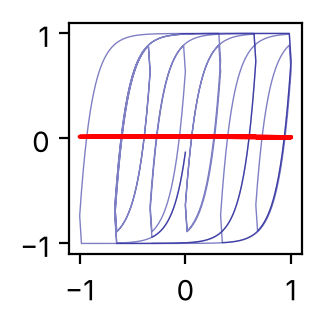

251  --  7.4517784
252  --  7.450859
253  --  7.4499454


254  --  7.4490376
255  --  7.448133


256  --  7.4472337
257  --  7.4463396
258  --  7.4454503
259  --  7.4445653
260  --  7.4436827
261  --  7.442803


262  --  7.4419236
263  --  7.4410434
264  --  7.4401636


265  --  7.439285
266  --  7.438406


267  --  7.4375253
268  --  7.4366455
269  --  7.4357653
270  --  7.4348845
271  --  7.434003
272  --  7.43312


... (4 outputs left out)

288  --  7.418604
289  --  7.417661
290  --  7.416722


291  --  7.415791
292  --  7.4148645
293  --  7.4139366
294  --  7.4130063
295  --  7.412073
296  --  7.4111376


297  --  7.410199
298  --  7.4092593
299  --  7.4083176


300  --  7.407373


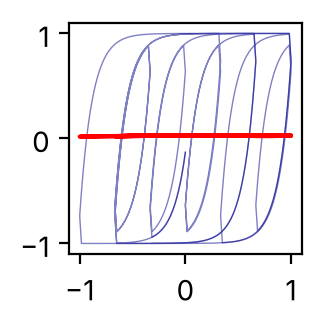

301  --  7.406426
302  --  7.405476
303  --  7.4045234
304  --  7.403567


305  --  7.402607
306  --  7.4016414
307  --  7.4006734
308  --  7.399703


309  --  7.3987284
310  --  7.397748
311  --  7.3967633
312  --  7.3957734


313  --  7.3947783
314  --  7.3937798
315  --  7.392778


316  --  7.3917737
317  --  7.390766
318  --  7.3897552
319  --  7.38874


320  --  7.3877215
321  --  7.3866982
322  --  7.3856726


... (4 outputs left out)

337  --  7.3699474
338  --  7.3688765
339  --  7.367802
340  --  7.366724
341  --  7.365642


342  --  7.364557
343  --  7.363468
344  --  7.362377


345  --  7.3612823
346  --  7.360184
347  --  7.359082


348  --  7.357978
349  --  7.356869
350  --  7.3557577


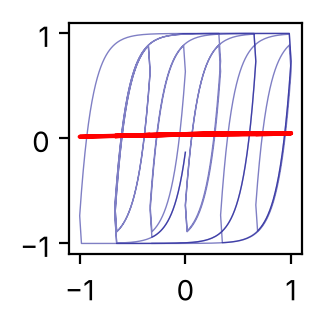

351  --  7.3546424
352  --  7.3535233
353  --  7.3524003


354  --  7.3512735
355  --  7.350144
356  --  7.349011


357  --  7.3478746
358  --  7.3467345
359  --  7.345591
360  --  7.344444
361  --  7.3432937


362  --  7.3421392
363  --  7.34098
364  --  7.339818


365  --  7.3386526
366  --  7.337483
367  --  7.336309


368  --  7.3351326
369  --  7.333953
370  --  7.3327703
371  --  7.3315835
372  --  7.3303943


... (5 outputs left out)

389  --  7.3097286
390  --  7.3084817
391  --  7.3072314
392  --  7.3059764


393  --  7.3047175
394  --  7.303451
395  --  7.3021793


396  --  7.300902
397  --  7.299615
398  --  7.298321


399  --  7.2970214
400  --  7.2957163


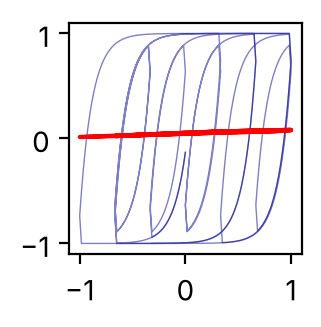

401  --  7.2944083
402  --  7.293101


403  --  7.2917943
404  --  7.290494
405  --  7.2891994


406  --  7.2879133
407  --  7.2866282
408  --  7.285344
409  --  7.2840595
410  --  7.2827744


411  --  7.2814884
412  --  7.280203


413  --  7.2789154
414  --  7.2776275
415  --  7.276338
416  --  7.27505


417  --  7.273761
418  --  7.272471
419  --  7.27118
420  --  7.269888
421  --  7.2685943


... (7 outputs left out)

440  --  7.243718
441  --  7.24239
442  --  7.24106
443  --  7.2397275


444  --  7.238393
445  --  7.237057
446  --  7.235718
447  --  7.234377


448  --  7.233034
449  --  7.2316885


450  --  7.23034


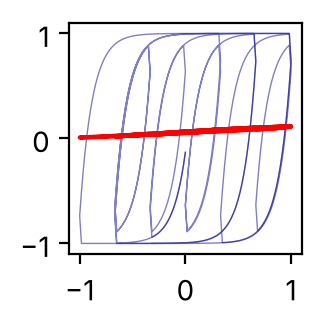

451  --  7.2289886
452  --  7.2276344
453  --  7.2262793


454  --  7.2249203
455  --  7.2235584
456  --  7.222194


457  --  7.2208257
458  --  7.219456
459  --  7.2180834


460  --  7.216707
461  --  7.2153277
462  --  7.2139473


463  --  7.212562
464  --  7.211174
465  --  7.2097826


466  --  7.208389
467  --  7.206992
468  --  7.2055917


... (7 outputs left out)

491  --  7.1722884
492  --  7.1707845
493  --  7.1692758


494  --  7.1677594
495  --  7.1662383


496  --  7.164713
497  --  7.16318
498  --  7.161643
499  --  7.160099


500  --  7.1585493


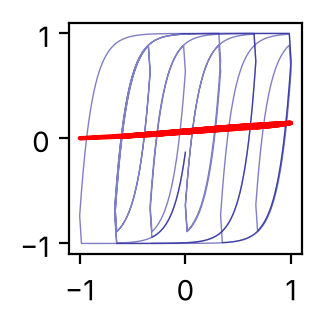

501  --  7.156994


502  --  7.1554317
503  --  7.1538653
504  --  7.1522923
505  --  7.150713
506  --  7.1491256
507  --  7.1475334


508  --  7.1459336
509  --  7.1443253
510  --  7.1427097


511  --  7.141087


512  --  7.139457
513  --  7.13782
514  --  7.136174
515  --  7.1345205
516  --  7.13286


517  --  7.1311903
518  --  7.1295123
519  --  7.127827


... (3 outputs left out)

534  --  7.101406
535  --  7.099558
536  --  7.097695
537  --  7.095821


538  --  7.0939417
539  --  7.092053
540  --  7.0901556
541  --  7.0882454
542  --  7.0863233
543  --  7.08439


544  --  7.0824428
545  --  7.0804844
546  --  7.0785108


547  --  7.076527
548  --  7.0745273
549  --  7.072517
550  --  7.0704894


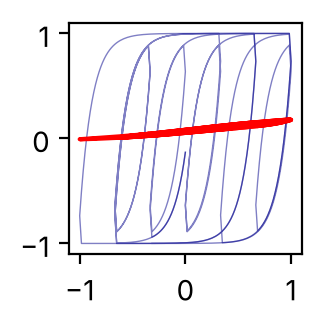

551  --  7.0684495
552  --  7.0663967
553  --  7.0643287
554  --  7.062246


555  --  7.0601473
556  --  7.058036
557  --  7.0559087
558  --  7.0537653
559  --  7.0516086
560  --  7.0494337


561  --  7.047244
562  --  7.0450363
563  --  7.0428133
564  --  7.0405726


565  --  7.038316
566  --  7.0360384
567  --  7.0337467
568  --  7.031432
569  --  7.029101
570  --  7.026747
571  --  7.024372


572  --  7.021972
573  --  7.0195503
574  --  7.0170984
575  --  7.014632


576  --  7.012153
577  --  7.0096564
578  --  7.007144
579  --  7.0046177
580  --  7.0020747
581  --  6.99951
582  --  6.9969254


583  --  6.9943166
584  --  6.991681
585  --  6.989027
586  --  6.986345


587  --  6.983634
588  --  6.980905
589  --  6.978154
590  --  6.9753804
591  --  6.972589
592  --  6.969775
593  --  6.966938
594  --  6.964076


595  --  6.961194
596  --  6.9582834
597  --  6.955346
598  --  6.9523845


599  --  6.949397
600  --  6.9463825


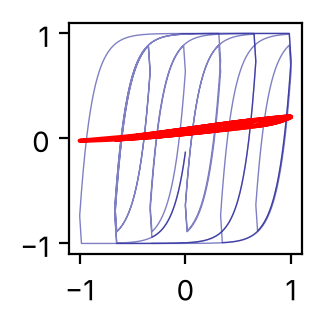

601  --  6.9433393
602  --  6.940271


603  --  6.937173
604  --  6.9340487
605  --  6.930895
606  --  6.927712


607  --  6.924501
608  --  6.9212584
609  --  6.9179864
610  --  6.9146876
611  --  6.911354
612  --  6.9079933


613  --  6.9045987
614  --  6.9011717


615  --  6.8977137
616  --  6.8942227
617  --  6.8907003
618  --  6.8871408


619  --  6.8835516
620  --  6.8799257
621  --  6.8762646
622  --  6.8725686
623  --  6.868838
624  --  6.8650703


... (4 outputs left out)

638  --  6.808277
639  --  6.8039145
640  --  6.7995043
641  --  6.795049


642  --  6.790549
643  --  6.786006
644  --  6.7814145
645  --  6.7767744
646  --  6.7720904
647  --  6.7673573


648  --  6.7625732
649  --  6.757741


650  --  6.75286


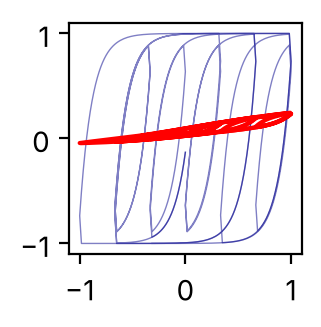

651  --  6.7479296


652  --  6.7429442
653  --  6.737912
654  --  6.7328258
655  --  6.727684
656  --  6.7224913
657  --  6.7172446


658  --  6.71194
659  --  6.706581
660  --  6.7011676


661  --  6.695695
662  --  6.690168
663  --  6.6845794


664  --  6.6789365
665  --  6.673228
666  --  6.6674614
667  --  6.661635
668  --  6.655744


669  --  6.649792
670  --  6.6437745
671  --  6.6376953


... (4 outputs left out)

685  --  6.5451865
686  --  6.537991
687  --  6.5307093
688  --  6.5233436
689  --  6.5158944


690  --  6.5083585
691  --  6.50074
692  --  6.4930387


693  --  6.4852543
694  --  6.4773855


695  --  6.4694304
696  --  6.4613857
697  --  6.4532666
698  --  6.4450603
699  --  6.4367642
700  --  6.428379


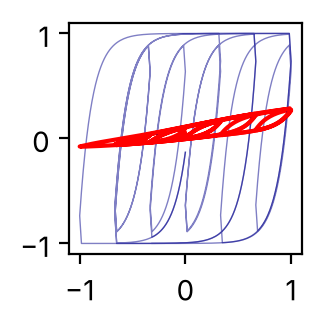

701  --  6.419912
702  --  6.4113483
703  --  6.4026937


704  --  6.3939404
705  --  6.385095
706  --  6.3761516
707  --  6.36711
708  --  6.3579655
709  --  6.3487186
710  --  6.3393717
711  --  6.329918
712  --  6.320361


713  --  6.3106956
714  --  6.300925
715  --  6.2910447


716  --  6.2810507
717  --  6.270945
718  --  6.26073
719  --  6.2503943
720  --  6.2399483
721  --  6.229382
722  --  6.2186975
723  --  6.207896


724  --  6.1969695
725  --  6.1859202
726  --  6.1747427


727  --  6.1634445
728  --  6.1520133
729  --  6.140458
730  --  6.1287694
731  --  6.1169486
732  --  6.1049943
733  --  6.092904
734  --  6.080679
735  --  6.068313


736  --  6.055808
737  --  6.043164
738  --  6.03038


739  --  6.0174484
740  --  6.0043755
741  --  5.9911523
742  --  5.9777813
743  --  5.964259
744  --  5.950587
745  --  5.936765
746  --  5.922786
747  --  5.908652


748  --  5.8943586
749  --  5.87991
750  --  5.8652983


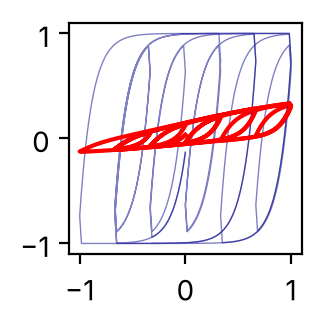

751  --  5.8505244
752  --  5.8355927
753  --  5.8204937
754  --  5.8052278
755  --  5.789789
756  --  5.7741866


757  --  5.7584133
758  --  5.742464
759  --  5.7263427
760  --  5.710044
761  --  5.693568
762  --  5.6769133


763  --  5.660072
764  --  5.643051
765  --  5.625848
766  --  5.608467
767  --  5.5908995
768  --  5.5731416
769  --  5.555203


770  --  5.537082
771  --  5.518778
772  --  5.5002894
773  --  5.481615
774  --  5.462753


775  --  5.443699
776  --  5.424456
777  --  5.40502
778  --  5.385394
779  --  5.3655744
780  --  5.345558
781  --  5.3253455


782  --  5.304941
783  --  5.2843404
784  --  5.2635417
785  --  5.2425485
786  --  5.2213573


787  --  5.1999702
788  --  5.1783843
789  --  5.1565957
790  --  5.1346107
791  --  5.1124287
792  --  5.09004


793  --  5.0674553
794  --  5.0446672
795  --  5.021682
796  --  4.9984965


797  --  4.975114
798  --  4.951534
799  --  4.927758
800  --  4.9037857


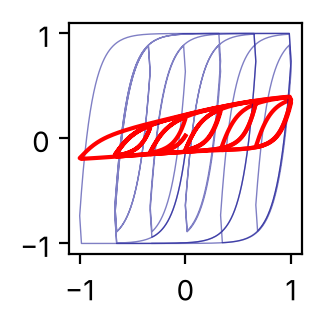

801  --  4.879616
802  --  4.855253
803  --  4.8306966


804  --  4.805936
805  --  4.780981
806  --  4.7558317
807  --  4.7304883
808  --  4.7049537
809  --  4.6792154
810  --  4.6533027
811  --  4.627176


812  --  4.6008883
813  --  4.574413
814  --  4.547752


815  --  4.520914
816  --  4.493894
817  --  4.466694
818  --  4.4393253
819  --  4.411778
820  --  4.384069
821  --  4.356195
822  --  4.328153


823  --  4.299955
824  --  4.271599
825  --  4.243094


826  --  4.21444
827  --  4.18564
828  --  4.1566916
829  --  4.1276174
830  --  4.0984044
831  --  4.0690613
832  --  4.0396004


833  --  4.0100107
834  --  3.9803016
835  --  3.950474


836  --  3.920535
837  --  3.8904855
838  --  3.86033
839  --  3.8300734
840  --  3.7997203
841  --  3.7692707
842  --  3.738734
843  --  3.7081158


844  --  3.6774228
845  --  3.6466517
846  --  3.6158164
847  --  3.5849152


848  --  3.553958
849  --  3.522948
850  --  3.49189


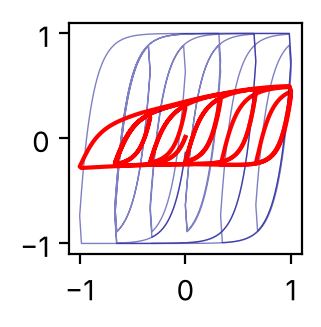

851  --  3.460785


852  --  3.4296384
853  --  3.3984568
854  --  3.3672493


855  --  3.3360167
856  --  3.3047621
857  --  3.273487
858  --  3.2421992
859  --  3.210903
860  --  3.1795945


861  --  3.1482828
862  --  3.1169689
863  --  3.085656
864  --  3.0543172


865  --  3.022983
866  --  2.9916701
867  --  2.9603755
868  --  2.9291096
869  --  2.8978708
870  --  2.866707


871  --  2.8356714
872  --  2.8048072
873  --  2.7740571
874  --  2.7433908


875  --  2.7128162
876  --  2.6823368
877  --  2.6519473
878  --  2.6216526
879  --  2.5914543
880  --  2.561356
881  --  2.5313637


882  --  2.5014853
883  --  2.4717352
884  --  2.44208
885  --  2.4125185
886  --  2.383048


887  --  2.353676
888  --  2.324457
889  --  2.2954364
890  --  2.2665725
891  --  2.2378852
892  --  2.209378


893  --  2.1810603
894  --  2.1529064
895  --  2.124935
896  --  2.0971525


897  --  2.0695815
898  --  2.0422063
899  --  2.015019
900  --  1.9880168


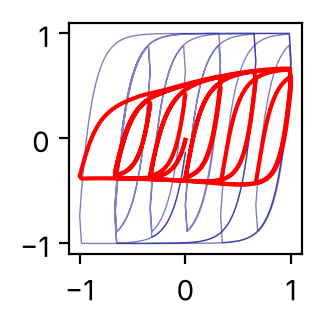

901  --  1.961217
902  --  1.9346217
903  --  1.9082149
904  --  1.8820198


905  --  1.8560125
906  --  1.8302063
907  --  1.8045993
908  --  1.7792017
909  --  1.7540122
910  --  1.7290297
911  --  1.7042859


912  --  1.6797495
913  --  1.6553868
914  --  1.6312567
915  --  1.6073463
916  --  1.58369


917  --  1.5602676
918  --  1.537077
919  --  1.5141146
920  --  1.4913862
921  --  1.468924
922  --  1.4467044
923  --  1.4247451


924  --  1.4030144
925  --  1.3815432
926  --  1.3603073
927  --  1.3393396
928  --  1.3186038


929  --  1.2981179
930  --  1.2778974
931  --  1.2578571
932  --  1.2380803
933  --  1.2185363
934  --  1.1992248
935  --  1.1801718
936  --  1.1613301


937  --  1.1426811
938  --  1.1242934
939  --  1.1061394
940  --  1.0881906
941  --  1.0704253


942  --  1.052873
943  --  1.0355374
944  --  1.0184323
945  --  1.0015291
946  --  0.98485994
947  --  0.96841013
948  --  0.952158
949  --  0.93608636


950  --  0.92024434


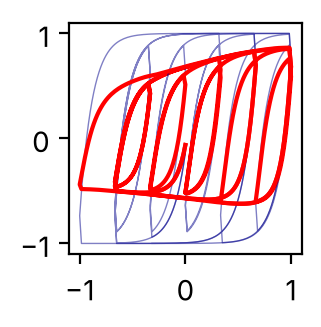

951  --  0.90460795
952  --  0.88920426


953  --  0.8740112
954  --  0.8590299
955  --  0.84424204
956  --  0.82967985
957  --  0.8153517
958  --  0.8012487
959  --  0.7873518
960  --  0.77365613


961  --  0.7601202
962  --  0.7467896
963  --  0.7336671


964  --  0.7207132


965  --  0.7079671
966  --  0.6954378
967  --  0.6831174
968  --  0.6710119
969  --  0.6590985
970  --  0.6473759
971  --  0.6358584
972  --  0.62453735


973  --  0.6134184
974  --  0.6024812
975  --  0.59172314


... (2 outputs left out)

986  --  0.4843737
987  --  0.4755772
988  --  0.4669106


989  --  0.45839208
990  --  0.45004606


991  --  0.4418652
992  --  0.4338393
993  --  0.42592725
994  --  0.41812697
995  --  0.41049126
996  --  0.40301242
997  --  0.39568642


998  --  0.38851768
999  --  0.38143972
1000  --  0.37443268


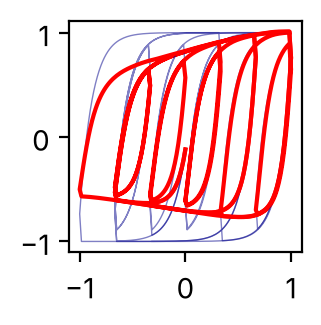

1001  --  0.3675647
1002  --  0.36080095
1003  --  0.35417846
1004  --  0.3476931
1005  --  0.34131506
1006  --  0.3350609
1007  --  0.32894766


1008  --  0.32298842
1009  --  0.31716585
1010  --  0.31148818
1011  --  0.30591848
1012  --  0.30050293


1013  --  0.29520798
1014  --  0.29004997
1015  --  0.2850036
1016  --  0.28006026
1017  --  0.27523714
1018  --  0.2705298
1019  --  0.26592803


1020  --  0.2614287
1021  --  0.2570204
1022  --  0.2527171
1023  --  0.24845773
1024  --  0.24427718


1025  --  0.240173
1026  --  0.23615533
1027  --  0.23221861
1028  --  0.22835867
1029  --  0.22455259
1030  --  0.22083671
1031  --  0.21720034


1032  --  0.21364589
1033  --  0.21017924
1034  --  0.2067776
1035  --  0.20345162
1036  --  0.20021516
1037  --  0.1970597


1038  --  0.19398183
1039  --  0.1909718
1040  --  0.1880283
1041  --  0.18516418
1042  --  0.18237717
1043  --  0.17965089
1044  --  0.1769965


1045  --  0.17441009
1046  --  0.17188969
1047  --  0.16943379
1048  --  0.16702992
1049  --  0.16469373


1050  --  0.16241945


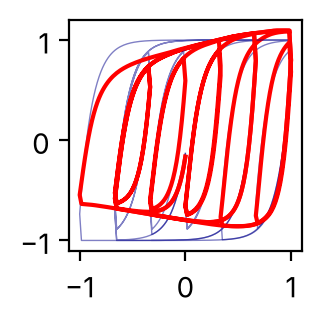

1051  --  0.16020967
1052  --  0.15805928
1053  --  0.15596539
1054  --  0.15392755


1055  --  0.15194842
1056  --  0.15002182
1057  --  0.14810646
1058  --  0.14624609
1059  --  0.14444911


1060  --  0.14272852
1061  --  0.1410739
1062  --  0.1394737


1063  --  0.13787468
1064  --  0.13626212
1065  --  0.13462444


1066  --  0.13297252
1067  --  0.13135515
1068  --  0.1297906
1069  --  0.12827753
1070  --  0.12681463
1071  --  0.1254033


1072  --  0.12403889
1073  --  0.122719996
1074  --  0.121427275


... (3 outputs left out)

1087  --  0.10746283
1088  --  0.10658316
1089  --  0.105726264


1090  --  0.104889296
1091  --  0.10406242
1092  --  0.10324639
1093  --  0.102437764
1094  --  0.10163838
1095  --  0.1008462
1096  --  0.10006659


1097  --  0.099297985
1098  --  0.09854224


1099  --  0.09780173
1100  --  0.09707902


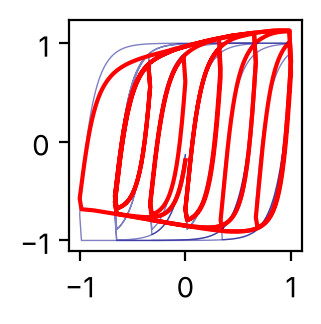

1101  --  0.09637161
1102  --  0.09568002
1103  --  0.09500301
1104  --  0.09433697
1105  --  0.09368501
1106  --  0.093046166


1107  --  0.09241895


1108  --  0.091802716
1109  --  0.09120042
1110  --  0.09060846
1111  --  0.09002206
1112  --  0.08944565


1113  --  0.088879354
1114  --  0.08831973
1115  --  0.08776673
1116  --  0.08721588
1117  --  0.08667283
1118  --  0.08613658


1119  --  0.085608914


1120  --  0.08508786
1121  --  0.08456717
1122  --  0.08405074
1123  --  0.08353802


... (3 outputs left out)

1136  --  0.0776098
1137  --  0.07719629
1138  --  0.07678502
1139  --  0.07637628
1140  --  0.075973704
1141  --  0.07557187


1142  --  0.075170405
1143  --  0.07477681


1144  --  0.074384816
1145  --  0.073993914
1146  --  0.0736113
1147  --  0.07323087


1148  --  0.07285258
1149  --  0.07248275
1150  --  0.072115436


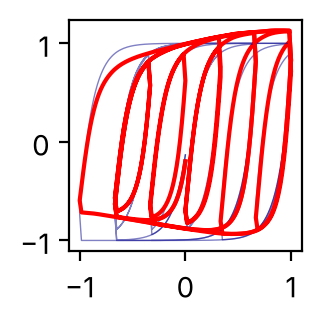

1151  --  0.07175177
1152  --  0.07139266


1153  --  0.071040384
1154  --  0.07068874
1155  --  0.07033912
1156  --  0.06999384
1157  --  0.06965024


1158  --  0.069308735
1159  --  0.068970844
1160  --  0.06863097
1161  --  0.0682965
1162  --  0.067963794
1163  --  0.06763347
1164  --  0.06730752


1165  --  0.066983424
1166  --  0.06665912


1167  --  0.066341355
1168  --  0.06602424
1169  --  0.065708086
1170  --  0.065392226
1171  --  0.0650702


1172  --  0.06470496
1173  --  0.06439169
1174  --  0.06407288
1175  --  0.06375228
1176  --  0.063433744
1177  --  0.0631138


... (2 outputs left out)

1185  --  0.060495526
1186  --  0.06019997
1187  --  0.0599103
1188  --  0.0596246
1189  --  0.05934673
1190  --  0.059069097


1191  --  0.058791358
1192  --  0.0585136


1193  --  0.058234107
1194  --  0.05795375
1195  --  0.057670955
1196  --  0.057387937
1197  --  0.05710515


1198  --  0.056823462
1199  --  0.05654453
1200  --  0.056266688


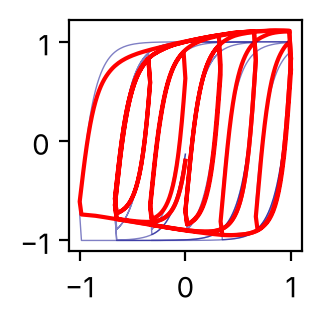

1201  --  0.05599046


1202  --  0.05571672
1203  --  0.055443734


1204  --  0.055172544
1205  --  0.054902352
1206  --  0.054634146
1207  --  0.054366533
1208  --  0.054098956


1209  --  0.053833283
1210  --  0.05356985
1211  --  0.05330713
1212  --  0.05304466
1213  --  0.052785173


1214  --  0.052527323


1215  --  0.052269805
1216  --  0.052014638


... (7 outputs left out)

1240  --  0.046291012
1241  --  0.04606733


1242  --  0.045844495
1243  --  0.045621995
1244  --  0.04540101


1245  --  0.045181412
1246  --  0.044963244
1247  --  0.044746015
1248  --  0.044529494
1249  --  0.044314884


1250  --  0.044101175


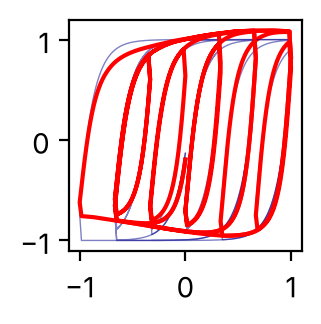

1251  --  0.043888282


1252  --  0.04367652
1253  --  0.043465488
1254  --  0.04325585
1255  --  0.04304743
1256  --  0.042839784
1257  --  0.042632952


1258  --  0.042427238
1259  --  0.042222187
1260  --  0.04201787
1261  --  0.041814636
1262  --  0.041612417


1263  --  0.041411035


1264  --  0.041210983
1265  --  0.04101188
1266  --  0.040814854
1267  --  0.04061716
1268  --  0.040421106


1269  --  0.040225238
1270  --  0.04003012
1271  --  0.03983745
1272  --  0.039644536
1273  --  0.039453752
1274  --  0.03926268


... (3 outputs left out)

1288  --  0.03670071


1289  --  0.036525384
1290  --  0.03635079
1291  --  0.0361768
1292  --  0.036004636
1293  --  0.035832692
1294  --  0.035662256


1295  --  0.035492342
1296  --  0.035323124
1297  --  0.03515601
1298  --  0.03498905
1299  --  0.034823343


1300  --  0.034657884


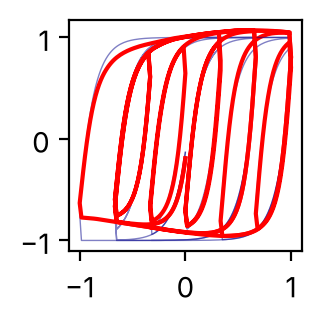

1301  --  0.034493223
1302  --  0.03433084
1303  --  0.03416853
1304  --  0.034007434


1305  --  0.03384701
1306  --  0.03368738
1307  --  0.033529755
1308  --  0.0333725
1309  --  0.03321676
1310  --  0.033061016


1311  --  0.032905813
1312  --  0.03275247
1313  --  0.032599278


1314  --  0.03244759
1315  --  0.032296084
1316  --  0.032146163
1317  --  0.031996906
1318  --  0.031848405


1319  --  0.031701684
1320  --  0.031555127
1321  --  0.031409618
1322  --  0.031264685
1323  --  0.031120487
1324  --  0.030978076


1325  --  0.030836033
1326  --  0.030695142
1327  --  0.03055416


... (2 outputs left out)

1337  --  0.029197842
1338  --  0.029066369
1339  --  0.028936792


1340  --  0.028807532
1341  --  0.028678762
1342  --  0.028551597
1343  --  0.028424699


1344  --  0.028298836
1345  --  0.028173972
1346  --  0.02804959
1347  --  0.027926834
1348  --  0.027804295


1349  --  0.027682846
1350  --  0.027561663


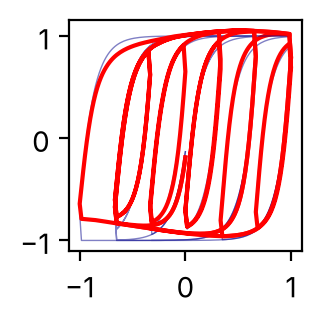

1351  --  0.027440999


1352  --  0.027321879
1353  --  0.027203247
1354  --  0.027085109
1355  --  0.026967874


1356  --  0.026852127
1357  --  0.026736498
1358  --  0.026621744
1359  --  0.026507586
1360  --  0.026393838
1361  --  0.02628151


1362  --  0.026169779


1363  --  0.026058378
1364  --  0.025948385
1365  --  0.02583913
1366  --  0.025730059
1367  --  0.025621962


1368  --  0.025514983
1369  --  0.025408229
1370  --  0.02530199
1371  --  0.025197279
1372  --  0.02509294
1373  --  0.024988828


... (4 outputs left out)

1387  --  0.023603082
1388  --  0.023510313
1389  --  0.023417685
1390  --  0.023325741
1391  --  0.023234716


1392  --  0.023144543
1393  --  0.023055691
1394  --  0.022966975
1395  --  0.022878712
1396  --  0.02279119
1397  --  0.022704495


1398  --  0.022619396


1399  --  0.022534754
1400  --  0.022450145


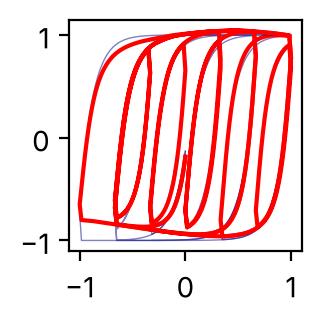

1401  --  0.022366894
1402  --  0.022283293
1403  --  0.022199987
1404  --  0.022117594
1405  --  0.022036746
1406  --  0.021956056


1407  --  0.021874929


1408  --  0.02179511
1409  --  0.021715606
1410  --  0.02163628
1411  --  0.021558173
1412  --  0.021480458
1413  --  0.0214027


1414  --  0.021326382
1415  --  0.021250898
1416  --  0.021175735
1417  --  0.021101845
1418  --  0.021028187


1419  --  0.020954607


1420  --  0.020882346
1421  --  0.02081033
1422  --  0.020738602
1423  --  0.020667704
1424  --  0.020596882
1425  --  0.020527454


... (2 outputs left out)

1432  --  0.020056237
1433  --  0.019990621
1434  --  0.019926375
1435  --  0.019862533
1436  --  0.019799137
1437  --  0.019736307


1438  --  0.01967329
1439  --  0.019611608
1440  --  0.019550659
1441  --  0.019490648


1442  --  0.01943098
1443  --  0.019371051
1444  --  0.019312667
1445  --  0.019254908
1446  --  0.019196786


1447  --  0.01913987
1448  --  0.019084074
1449  --  0.019028494
1450  --  0.01897237


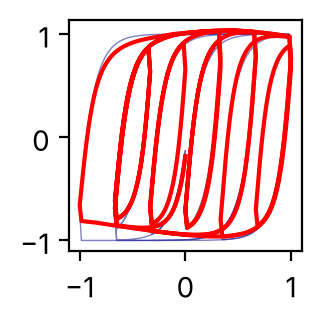

1451  --  0.018917268
1452  --  0.01886223
1453  --  0.018806515


1454  --  0.01875137
1455  --  0.01869669
1456  --  0.018641772
1457  --  0.018586135
1458  --  0.018530972
1459  --  0.018476576
1460  --  0.018422792
1461  --  0.01836816


1462  --  0.018313209
1463  --  0.018260077
1464  --  0.018206917
1465  --  0.018153347


1466  --  0.018100632
1467  --  0.018049285
1468  --  0.017997626
1469  --  0.01794607
1470  --  0.017895311
1471  --  0.01784508
1472  --  0.017795764
1473  --  0.017746506
1474  --  0.01769698


1475  --  0.01764836
1476  --  0.017600752
1477  --  0.017552825
1478  --  0.017504836


1479  --  0.017458139
1480  --  0.017411886
1481  --  0.017365389
1482  --  0.017320065
1483  --  0.01727625
1484  --  0.017232578
1485  --  0.017189346
1486  --  0.017148344


1487  --  0.017108843
1488  --  0.017070085
1489  --  0.017034141
1490  --  0.017000414


1491  --  0.016967276
1492  --  0.01693477
1493  --  0.016903669
1494  --  0.016871931
1495  --  0.016837765
1496  --  0.016802007
1497  --  0.016762888
1498  --  0.016718574
1499  --  0.016669694


1500  --  0.016618289


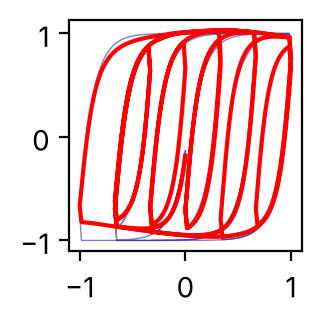

1501  --  0.016565118
1502  --  0.016511498
1503  --  0.016458483
1504  --  0.016406827
1505  --  0.016356962
1506  --  0.016309058
1507  --  0.016264044
1508  --  0.016220938
1509  --  0.016180867
1510  --  0.01614325


1511  --  0.016107656
1512  --  0.016073523


1513  --  0.016040273
1514  --  0.016006911
1515  --  0.015973067
1516  --  0.015936825
1517  --  0.015899789
1518  --  0.015861444
1519  --  0.01582147
1520  --  0.015780127
1521  --  0.015737241
1522  --  0.015694788


1523  --  0.015652047
1524  --  0.015610498


1525  --  0.015571895
1526  --  0.015536668
1527  --  0.015505521
1528  --  0.015480934
1529  --  0.015463509
1530  --  0.015454506
1531  --  0.01545307
1532  --  0.015458092
1533  --  0.015463927
1534  --  0.015464786
1535  --  0.01545451


1536  --  0.015424696
1537  --  0.015378357


1538  --  0.01531792
1539  --  0.015249208
1540  --  0.0151781505
1541  --  0.015110241
1542  --  0.015048402
1543  --  0.014993421
1544  --  0.014945135
1545  --  0.014903625
1546  --  0.0148661
1547  --  0.014832755


1548  --  0.014801792
1549  --  0.014771815


1550  --  0.014741956


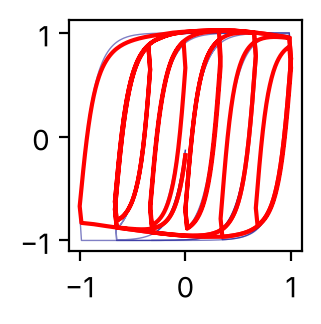

1551  --  0.014711705
1552  --  0.014680708
1553  --  0.01464884
1554  --  0.014616083
1555  --  0.014582667
1556  --  0.0145494845
1557  --  0.014515618


1558  --  0.014481688
1559  --  0.014449488


1560  --  0.014417931
1561  --  0.014388253
1562  --  0.014360448
1563  --  0.014334273
1564  --  0.01430924


1565  --  0.014285611
1566  --  0.014263674
1567  --  0.014241573
1568  --  0.014220139
1569  --  0.014199316
1570  --  0.014177363
1571  --  0.014152788


1572  --  0.014126885
1573  --  0.014099419


1574  --  0.014069123
1575  --  0.014037396
1576  --  0.0140040405
1577  --  0.013969626


1578  --  0.013935331
1579  --  0.013900922
1580  --  0.013865582
1581  --  0.013831137
1582  --  0.013798146
1583  --  0.013765196
1584  --  0.013733447


1585  --  0.013702646
1586  --  0.013672439
1587  --  0.013642686


1588  --  0.013613231
1589  --  0.013584817
1590  --  0.013556977
1591  --  0.013529277


1592  --  0.013501119
1593  --  0.013474025
1594  --  0.0134466225
1595  --  0.01341996
1596  --  0.013393824
1597  --  0.013368522
1598  --  0.013344327


1599  --  0.013320189
1600  --  0.013296612


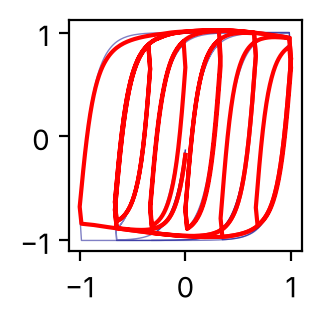

1601  --  0.013274885


1602  --  0.013253535
1603  --  0.013231098
1604  --  0.013209762
1605  --  0.013188777
1606  --  0.013167036
1607  --  0.01314623
1608  --  0.013125072


1609  --  0.013101773
1610  --  0.013077774
1611  --  0.013052944
1612  --  0.013026138
1613  --  0.012998494


1614  --  0.012969864


1615  --  0.0129403565
1616  --  0.012910532
1617  --  0.012880934
1618  --  0.012850961
1619  --  0.012821692
1620  --  0.012791979
1621  --  0.012763218


1622  --  0.012735015
1623  --  0.012707609
1624  --  0.012680702
1625  --  0.0126541685


... (2 outputs left out)

1634  --  0.01243556
1635  --  0.012413758
1636  --  0.012392077
1637  --  0.012371584
1638  --  0.012350903


1639  --  0.01233123


1640  --  0.0123122465
1641  --  0.012293946
1642  --  0.012276773
1643  --  0.012260415
1644  --  0.012243943
1645  --  0.012226557


1646  --  0.012208855
1647  --  0.012190867
1648  --  0.012171463
1649  --  0.0121521065
1650  --  0.012131452


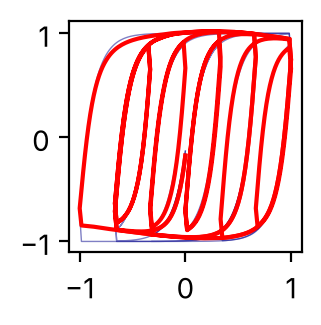

1651  --  0.012107699
1652  --  0.012083664
1653  --  0.012057566
1654  --  0.012030767
1655  --  0.01200357


1656  --  0.01197632
1657  --  0.011949029
1658  --  0.01192218
1659  --  0.0118961735
1660  --  0.011871025
1661  --  0.011846689
1662  --  0.0118233
1663  --  0.011800922


1664  --  0.01177954
1665  --  0.01175947
1666  --  0.011738179
1667  --  0.01171795
1668  --  0.011697934


1669  --  0.011678153
1670  --  0.011658134
1671  --  0.01163811
1672  --  0.011618157
1673  --  0.011598804
1674  --  0.01157899
1675  --  0.0115603395


1676  --  0.0115439845
1677  --  0.011528973
1678  --  0.011516205
1679  --  0.011507858


1680  --  0.011504097
1681  --  0.011505406
1682  --  0.011510049
1683  --  0.011519383
1684  --  0.011530333
1685  --  0.011538704
1686  --  0.011542828
1687  --  0.011537474


1688  --  0.011520529
1689  --  0.011491949
1690  --  0.011453106
1691  --  0.011406689


1692  --  0.011356517
1693  --  0.011307718
1694  --  0.011263098
1695  --  0.011224581
1696  --  0.0111924615
1697  --  0.011166018
1698  --  0.011144511


1699  --  0.011127316
1700  --  0.01111175


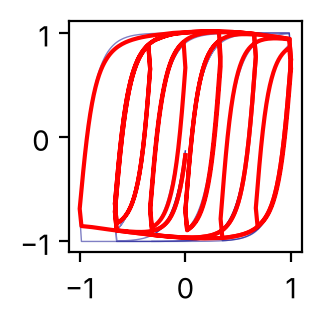

1701  --  0.011097686
1702  --  0.011084074
1703  --  0.011069765
1704  --  0.011054089
1705  --  0.011036747


1706  --  0.011017658
1707  --  0.01099698
1708  --  0.010975371
1709  --  0.010953903
1710  --  0.010932305
1711  --  0.010912439


1712  --  0.010895407
1713  --  0.010880842
1714  --  0.010870268
1715  --  0.01086464
1716  --  0.01086341


1717  --  0.010865822
1718  --  0.010872607
1719  --  0.01088127
1720  --  0.0108871
1721  --  0.010890133
1722  --  0.010886756


1723  --  0.010875053
1724  --  0.01085471
1725  --  0.010826934
1726  --  0.010793714
1727  --  0.01075691


1728  --  0.010719187
1729  --  0.010683658
1730  --  0.010649675
1731  --  0.010619459
1732  --  0.010592966
1733  --  0.01056964
1734  --  0.010549146


1735  --  0.010530617
1736  --  0.010513621
1737  --  0.010497565
1738  --  0.010482186


1739  --  0.010466012
1740  --  0.010450247
1741  --  0.010434524
1742  --  0.010418822
1743  --  0.010403382
1744  --  0.010388425
1745  --  0.010374438


1746  --  0.010360478
1747  --  0.0103478255
1748  --  0.010336607
1749  --  0.010327217


1750  --  0.010318308


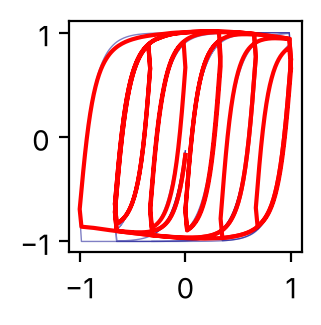

1751  --  0.0103100585
1752  --  0.01030324
1753  --  0.010297208


1754  --  0.010290747
1755  --  0.0102826245
1756  --  0.010273049
1757  --  0.010261871


1758  --  0.010248563
1759  --  0.010232011
1760  --  0.010214157
1761  --  0.010194122


1762  --  0.010172757
1763  --  0.010150471
1764  --  0.01012836
1765  --  0.01010654


1766  --  0.0100858
1767  --  0.010065759
1768  --  0.010047072
1769  --  0.0100293085


1770  --  0.01001258
1771  --  0.009996749
1772  --  0.0099819405
1773  --  0.009966682


... (4 outputs left out)

1789  --  0.009784602
1790  --  0.00977892
1791  --  0.009772727
1792  --  0.009764677


1793  --  0.009754627
1794  --  0.009742622
1795  --  0.009729643
1796  --  0.00971458


1797  --  0.009696714
1798  --  0.009676591


1799  --  0.009655924
1800  --  0.009634598


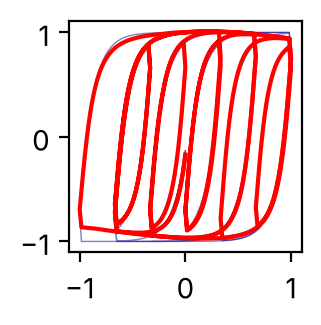

1801  --  0.009613751
1802  --  0.009593448
1803  --  0.00957415


1804  --  0.00955605


1805  --  0.009539571
1806  --  0.009524397
1807  --  0.009509609
1808  --  0.0094960695
1809  --  0.00948341


1810  --  0.009471215
1811  --  0.00945948
1812  --  0.00944809


1813  --  0.009436114


1814  --  0.009423002
1815  --  0.009409604
1816  --  0.009395762
1817  --  0.009381801
1818  --  0.009366981
1819  --  0.009352717


... (3 outputs left out)

1831  --  0.00933081
1832  --  0.009333336
1833  --  0.009329909
1834  --  0.009317257


1835  --  0.009296784
1836  --  0.009268686
1837  --  0.009235066
1838  --  0.009199183
1839  --  0.009163427
1840  --  0.0091303345
1841  --  0.009101915


1842  --  0.009078736
1843  --  0.009060572
1844  --  0.009047162
1845  --  0.009037646
1846  --  0.009031399


1847  --  0.0090261055
1848  --  0.009020943
1849  --  0.009015699
1850  --  0.0090092495


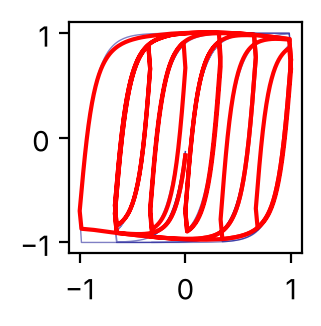

1851  --  0.009000527
1852  --  0.008989016
1853  --  0.008974986


1854  --  0.008957693
1855  --  0.008938376
1856  --  0.008918199
1857  --  0.008898388
1858  --  0.008879297
1859  --  0.008863269
1860  --  0.008850197
1861  --  0.00884213


1862  --  0.008840057
1863  --  0.008842637
1864  --  0.008851538


1865  --  0.008864677
1866  --  0.00888121
1867  --  0.008898258
1868  --  0.0089112185
1869  --  0.00891619
1870  --  0.008911656
1871  --  0.008895631
1872  --  0.008868417


1873  --  0.008832677
1874  --  0.00879304
1875  --  0.008753595


1876  --  0.008716947
1877  --  0.0086853
1878  --  0.008659858
1879  --  0.008640446
1880  --  0.008626588
1881  --  0.008615916
1882  --  0.008608425
1883  --  0.008602751


1884  --  0.008597587
1885  --  0.00859167


1886  --  0.008584132
1887  --  0.008574438
1888  --  0.008562396
1889  --  0.008548447
1890  --  0.008532946
1891  --  0.008516546
1892  --  0.008499983
1893  --  0.008483409


1894  --  0.008468694


1895  --  0.008456576
1896  --  0.00844702
1897  --  0.008441571
1898  --  0.008438066
1899  --  0.008438883
1900  --  0.008442922


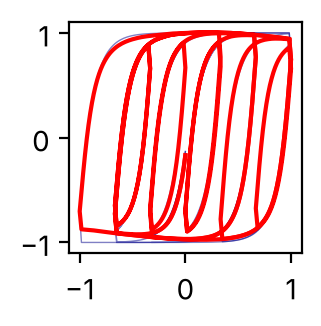

1901  --  0.008447715


1902  --  0.008453067
1903  --  0.008455634
1904  --  0.008456268
1905  --  0.008452453
1906  --  0.008442579
1907  --  0.008427573
1908  --  0.008406651
1909  --  0.008382685
1910  --  0.008357645
1911  --  0.008332796


1912  --  0.008308462


1913  --  0.008286894
1914  --  0.008268184
1915  --  0.008252622
1916  --  0.008239754
1917  --  0.00822902
1918  --  0.008220134
1919  --  0.008212478
1920  --  0.008205701
1921  --  0.0081990715
1922  --  0.008191943


1923  --  0.008183816


1924  --  0.008174341
1925  --  0.00816349
1926  --  0.008151304
1927  --  0.008137989
1928  --  0.008124639
1929  --  0.008109904
1930  --  0.008096321
1931  --  0.008084286
1932  --  0.008073548
1933  --  0.008066053


1934  --  0.008061921


1935  --  0.008060788
1936  --  0.008064378
1937  --  0.008070355
1938  --  0.00807801
1939  --  0.008087687
1940  --  0.008096312
1941  --  0.008102125
1942  --  0.008102675
1943  --  0.008095876
1944  --  0.008081976
1945  --  0.008061571
1946  --  0.00803604


1947  --  0.008007299


1948  --  0.007978128
1949  --  0.00794992
1950  --  0.007924658


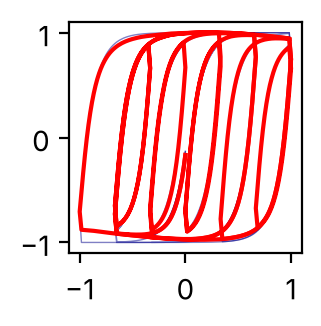

1951  --  0.007903998
1952  --  0.007888012
1953  --  0.007876552
1954  --  0.0078692725
1955  --  0.007865354


1956  --  0.007863575


1957  --  0.007863274
1958  --  0.0078623295
1959  --  0.007860401
1960  --  0.007856439
1961  --  0.007849561


1962  --  0.007839194
1963  --  0.00782556
1964  --  0.0078091472
1965  --  0.0077911317


1966  --  0.0077719353


1967  --  0.007753662
1968  --  0.007737021
1969  --  0.0077242884
1970  --  0.0077157537
1971  --  0.007712315


... (5 outputs left out)

1989  --  0.00755199
1990  --  0.007547427
1991  --  0.0075465566
1992  --  0.00754739
1993  --  0.0075486004


1994  --  0.0075485306
1995  --  0.0075458596
1996  --  0.0075395983
1997  --  0.007530018
1998  --  0.007516323


1999  --  0.007499974


2000  --  0.0074819336


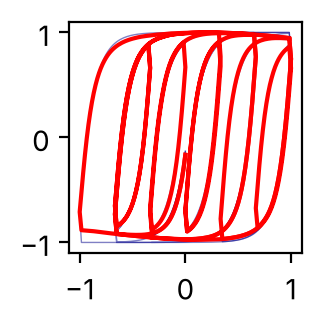

2001  --  0.0074635153
2002  --  0.007445942


2003  --  0.007430541
2004  --  0.0074184746
2005  --  0.0074110623
2006  --  0.0074081933
2007  --  0.0074104345


2008  --  0.0074164825


2009  --  0.0074250926
2010  --  0.0074353404
2011  --  0.007445943


2012  --  0.0074543753
2013  --  0.0074559553


2014  --  0.0074517713
2015  --  0.0074402136
2016  --  0.0074220053
2017  --  0.007399325


... (8 outputs left out)

2042  --  0.007136307


2043  --  0.007141461
2044  --  0.0071491157
2045  --  0.0071587367


2046  --  0.0071671167
2047  --  0.007173496
2048  --  0.007176489


2049  --  0.007173987
2050  --  0.0071637044


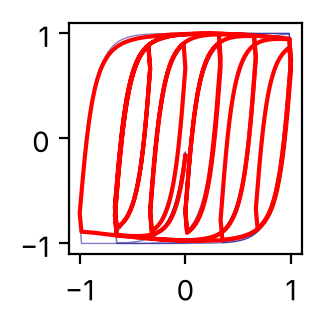

2051  --  0.0071478877
2052  --  0.007127224


2053  --  0.0071036494


2054  --  0.0070791044
2055  --  0.007055308
2056  --  0.007034161


2057  --  0.007016766
2058  --  0.0070035253
2059  --  0.0069945673


2060  --  0.0069883117
2061  --  0.0069854246
2062  --  0.0069846823


2063  --  0.0069850483
2064  --  0.006985441


... (10 outputs left out)

2091  --  0.006791306
2092  --  0.006769483
2093  --  0.006754157


2094  --  0.006745431
2095  --  0.006742391
2096  --  0.0067437724


2097  --  0.0067479885
2098  --  0.00675338
2099  --  0.0067581194


2100  --  0.0067602773


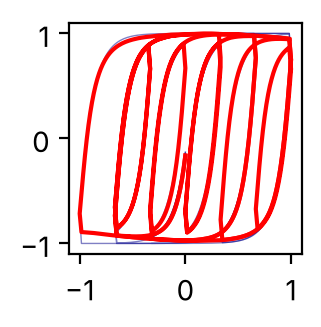

2101  --  0.0067585446
2102  --  0.00675194


2103  --  0.006740412
2104  --  0.0067251185


2105  --  0.0067062406
2106  --  0.006686229
2107  --  0.0066666203
2108  --  0.006649812


2109  --  0.0066378387
2110  --  0.0066309148
2111  --  0.006630054


2112  --  0.006635984
2113  --  0.00664714


2114  --  0.0066635646
2115  --  0.0066813403


... (9 outputs left out)

2142  --  0.0064246957
2143  --  0.0064180344
2144  --  0.006415788


2145  --  0.0064184116
2146  --  0.006424068


2147  --  0.0064330758
2148  --  0.0064445194


2149  --  0.0064557176
2150  --  0.006464903


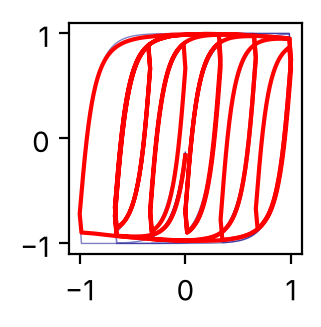

2151  --  0.006469212
2152  --  0.006468161


2153  --  0.0064603635


2154  --  0.0064454526


2155  --  0.0064259972
2156  --  0.0064036436
2157  --  0.006379885
2158  --  0.0063575637
2159  --  0.0063383463


2160  --  0.006323053
2161  --  0.0063120644


2162  --  0.0063051116


... (14 outputs left out)

2194  --  0.00612156
2195  --  0.0061103776


2196  --  0.0061045787


2197  --  0.0061030495


2198  --  0.0061045145
2199  --  0.006107438
2200  --  0.006110587


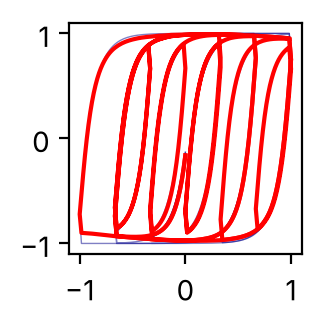

2201  --  0.0061123883


2202  --  0.006111574
2203  --  0.0061074337
2204  --  0.0060996097
2205  --  0.0060883667
2206  --  0.0060745454
2207  --  0.00605931
2208  --  0.0060440795


2209  --  0.0060304385


2210  --  0.0060200766
2211  --  0.0060145194
2212  --  0.006014586
2213  --  0.0060208244
2214  --  0.00603233
2215  --  0.0060488335
2216  --  0.0060683


2217  --  0.0060879844


2218  --  0.0061039976
2219  --  0.006112058
2220  --  0.0061107734
2221  --  0.006098884
2222  --  0.00607706
2223  --  0.006049163
2224  --  0.006018922


... (4 outputs left out)

2237  --  0.00591852


2238  --  0.0059070108
2239  --  0.0058928477
2240  --  0.0058777505
2241  --  0.005863495
2242  --  0.005851134
2243  --  0.005842919
2244  --  0.0058395695
2245  --  0.0058417674


2246  --  0.0058492613


2247  --  0.005862074
2248  --  0.0058776666
2249  --  0.0058943173
2250  --  0.005909405


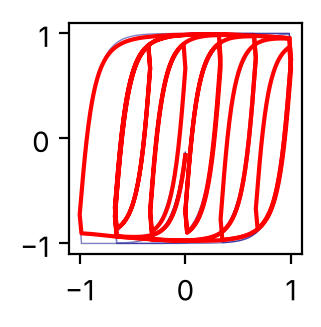

2251  --  0.005918958


2252  --  0.0059206714
2253  --  0.005913897
2254  --  0.0058988747
2255  --  0.005877359
2256  --  0.0058522383
2257  --  0.0058261524
2258  --  0.005801802
2259  --  0.005781374
2260  --  0.005766104


2261  --  0.005755956


2262  --  0.005750538
2263  --  0.0057488517
2264  --  0.0057490775
2265  --  0.0057498165
2266  --  0.00574964
2267  --  0.00574764
2268  --  0.005743205
2269  --  0.0057362006
2270  --  0.00572695


2271  --  0.0057161283


2272  --  0.005704933
2273  --  0.005693864
2274  --  0.005684672
2275  --  0.005678685
2276  --  0.005677359
2277  --  0.005680479
2278  --  0.0056873257
2279  --  0.0056981696
2280  --  0.0057121143


2281  --  0.005725945
2282  --  0.0057389825
2283  --  0.005748284
2284  --  0.00575071
2285  --  0.005744909
2286  --  0.005731674
2287  --  0.0057122847
2288  --  0.0056891763
2289  --  0.005664909


2290  --  0.0056417002
2291  --  0.005621736
2292  --  0.0056059402
2293  --  0.0055952775
2294  --  0.0055892374
2295  --  0.005586807
2296  --  0.0055870004
2297  --  0.005588308


2298  --  0.005589421
2299  --  0.005589288
2300  --  0.0055870065


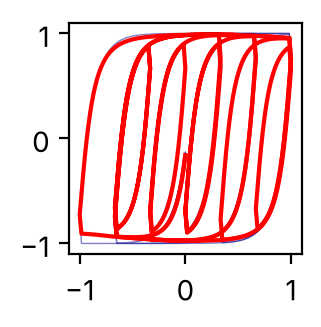

2301  --  0.005582187
2302  --  0.0055747107
2303  --  0.0055649555


2304  --  0.0055537242
2305  --  0.0055422783
2306  --  0.005531194
2307  --  0.005522529
2308  --  0.0055176946
2309  --  0.0055175563


2310  --  0.0055222004
2311  --  0.0055313115
2312  --  0.005544017


2313  --  0.0055598696
2314  --  0.0055755577
2315  --  0.0055888663
2316  --  0.005597777
2317  --  0.00559848
2318  --  0.0055906866


2319  --  0.005574769
2320  --  0.0055523803
2321  --  0.0055265077
2322  --  0.0055009276


2323  --  0.0054778354
2324  --  0.0054592853
2325  --  0.0054461877
2326  --  0.005439059
2327  --  0.0054375567
2328  --  0.0054400982


... (2 outputs left out)

2338  --  0.0053929593
2339  --  0.005380388
2340  --  0.005371497
2341  --  0.005368026


2342  --  0.0053716456
2343  --  0.005381587
2344  --  0.0053978595
2345  --  0.0054176757
2346  --  0.0054389043


2347  --  0.005457989
2348  --  0.005471388
2349  --  0.005475464


2350  --  0.0054686554


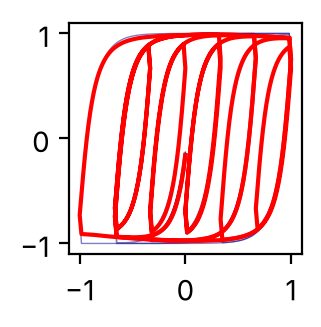

2351  --  0.005451032
2352  --  0.0054258197


2353  --  0.005396286
2354  --  0.005366349
2355  --  0.0053397105


2356  --  0.0053190654
2357  --  0.005305448
2358  --  0.0052982825


2359  --  0.005296586
2360  --  0.0052989023
2361  --  0.005303584
2362  --  0.005308356


2363  --  0.005311305
2364  --  0.005311164


2365  --  0.0053071124
2366  --  0.005299145
2367  --  0.0052878917


... (4 outputs left out)

2384  --  0.0052621136
2385  --  0.0052372036
2386  --  0.005213732
2387  --  0.0051932507
2388  --  0.005177988
2389  --  0.0051683877


2390  --  0.005164028
2391  --  0.005163554
2392  --  0.0051654275


2393  --  0.00516808
2394  --  0.005169812
2395  --  0.0051696314
2396  --  0.005166832
2397  --  0.00516098
2398  --  0.0051524737


2399  --  0.0051419754
2400  --  0.005130715


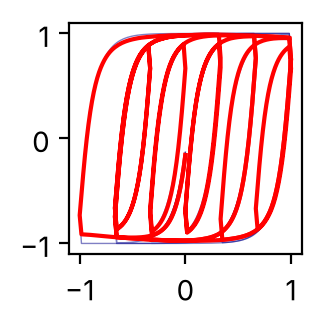

2401  --  0.005120149
2402  --  0.0051119975
2403  --  0.005107246
2404  --  0.0051069134
2405  --  0.005111223


2406  --  0.0051208865
2407  --  0.00513407
2408  --  0.005149528
2409  --  0.0051652836


2410  --  0.0051776674
2411  --  0.005184756
2412  --  0.005184595
2413  --  0.0051762853


2414  --  0.005160327
2415  --  0.0051392405
2416  --  0.0051157326
2417  --  0.0050925342


2418  --  0.0050723194
2419  --  0.00505662
2420  --  0.0050460952
2421  --  0.005040768


2422  --  0.0050399485
2423  --  0.005042218
2424  --  0.0050459486
2425  --  0.0050492943
2426  --  0.005050974


2427  --  0.005049972
2428  --  0.0050457027
2429  --  0.0050379825
2430  --  0.005027416
2431  --  0.0050151744


2432  --  0.0050029345
2433  --  0.004992665
2434  --  0.004985751
2435  --  0.0049836356
2436  --  0.0049865716
2437  --  0.0049950248


2438  --  0.0050087827
2439  --  0.0050264425
2440  --  0.0050450303
2441  --  0.005062127
2442  --  0.005073697
2443  --  0.005076997


2444  --  0.005071029
2445  --  0.0050563114
2446  --  0.005034766
2447  --  0.005009533
2448  --  0.004983824


2449  --  0.004961046
2450  --  0.0049433904


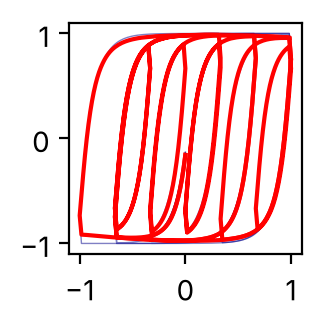

2451  --  0.004931485
2452  --  0.0049257763


2453  --  0.0049252845
2454  --  0.0049284645
2455  --  0.0049334364
2456  --  0.004938279
2457  --  0.0049411748


2458  --  0.004940713
2459  --  0.0049364273
2460  --  0.004928379
2461  --  0.0049169953


2462  --  0.0049036704
2463  --  0.004890281


2464  --  0.004878973
2465  --  0.004871655
2466  --  0.004869929
2467  --  0.0048740227
2468  --  0.004884583
2469  --  0.004900249


2470  --  0.0049198335
2471  --  0.0049402793
2472  --  0.004957837
2473  --  0.004968822


... (3 outputs left out)

2486  --  0.0048247674
2487  --  0.0048291036


2488  --  0.004830725
2489  --  0.004828653
2490  --  0.0048224465
2491  --  0.0048125726
2492  --  0.0048002335


2493  --  0.0047871373
2494  --  0.0047750906
2495  --  0.0047659045
2496  --  0.0047613224
2497  --  0.004762955


2498  --  0.0047704503
2499  --  0.0047832676
2500  --  0.004800574


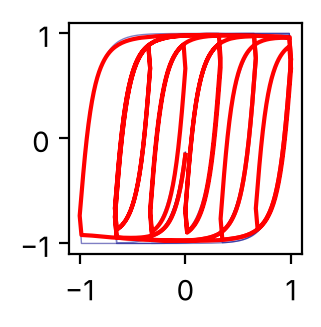

2501  --  0.0048201494
2502  --  0.0048381123


2503  --  0.004851564
2504  --  0.0048574475
2505  --  0.0048537035
2506  --  0.0048408043
2507  --  0.0048203557


2508  --  0.0047953385
2509  --  0.0047698813
2510  --  0.004746702
2511  --  0.004728345
2512  --  0.004716229
2513  --  0.0047104913
2514  --  0.004710042


2515  --  0.0047132806
2516  --  0.0047182087
2517  --  0.004722685
2518  --  0.004724907
2519  --  0.004723797


2520  --  0.004718943
2521  --  0.0047105635
2522  --  0.0046996274
2523  --  0.0046876995
2524  --  0.004676082
2525  --  0.0046670744
2526  --  0.004662131
2527  --  0.004662426


2528  --  0.004668741
2529  --  0.004680432
2530  --  0.0046965424
2531  --  0.0047149933
2532  --  0.0047329036


2533  --  0.004746778
2534  --  0.004753152
2535  --  0.004750514
2536  --  0.0047386927
2537  --  0.0047193323


2538  --  0.0046957154
2539  --  0.004671418
2540  --  0.004649177
2541  --  0.0046314774
2542  --  0.0046202214


2543  --  0.0046150996
2544  --  0.0046152463
2545  --  0.0046192743
2546  --  0.004625038
2547  --  0.00463052
2548  --  0.004633795


2549  --  0.0046335356
2550  --  0.0046292064


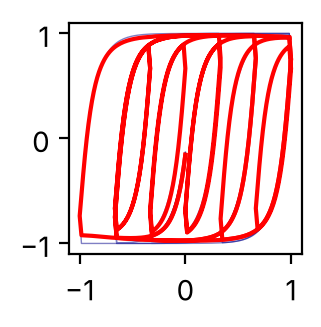

2551  --  0.0046209134
2552  --  0.0046095964
2553  --  0.0045967996
2554  --  0.0045843897
2555  --  0.0045744013
2556  --  0.0045687025
2557  --  0.004568933


2558  --  0.004576073
2559  --  0.0045892247
2560  --  0.004607068
2561  --  0.004627417
2562  --  0.004647061
2563  --  0.004661913


2564  --  0.0046682535
2565  --  0.0046647512
2566  --  0.004651266
2567  --  0.0046294588
2568  --  0.0046035927
2569  --  0.0045773266


2570  --  0.004554408
2571  --  0.004537186
2572  --  0.0045271465
2573  --  0.0045239134
2574  --  0.0045262994


2575  --  0.0045324476
2576  --  0.00454014
2577  --  0.0045468244
2578  --  0.004550315
2579  --  0.004549484
2580  --  0.0045439387


2581  --  0.004533971
2582  --  0.004520904
2583  --  0.0045066983
2584  --  0.0044935965
2585  --  0.004483804


2586  --  0.004479312
2587  --  0.0044818674
2588  --  0.004491025
2589  --  0.0045059295
2590  --  0.004524877
2591  --  0.0045449925


2592  --  0.004562578
2593  --  0.0045739724
2594  --  0.004576322
2595  --  0.004568636
2596  --  0.0045515643


2597  --  0.004527743
2598  --  0.004501826
2599  --  0.0044771326
2600  --  0.0044571594


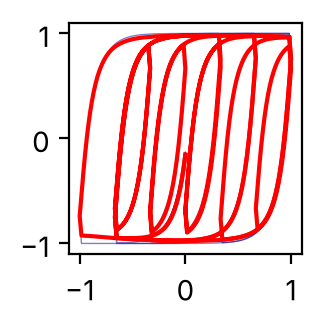

2601  --  0.00444414
2602  --  0.0044384454


2603  --  0.004439222
2604  --  0.004444652
2605  --  0.004452547
2606  --  0.0044602607
2607  --  0.00446544
2608  --  0.0044664363
2609  --  0.0044625513


2610  --  0.004453973
2611  --  0.0044418424


2612  --  0.004428022
2613  --  0.0044146557
2614  --  0.004403996
2615  --  0.004398001
2616  --  0.004398666
2617  --  0.004406309
2618  --  0.0044201803


2619  --  0.0044383085
2620  --  0.004458705


2621  --  0.004477577
2622  --  0.004490811
2623  --  0.004495357
2624  --  0.0044894307
2625  --  0.0044737775
2626  --  0.0044508954


... (2 outputs left out)

2635  --  0.00438159
2636  --  0.004387233


2637  --  0.0043886597
2638  --  0.0043850844
2639  --  0.0043766964
2640  --  0.0043646316
2641  --  0.004350747
2642  --  0.004337263
2643  --  0.004326432
2644  --  0.004320323


2645  --  0.0043206904
2646  --  0.0043277815


2647  --  0.0043411586
2648  --  0.004358996
2649  --  0.004378257
2650  --  0.004395781


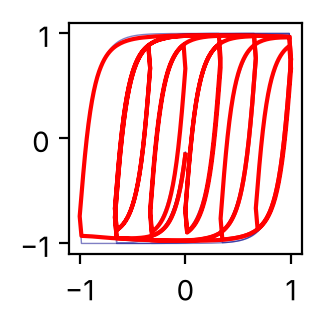

2651  --  0.0044073276
2652  --  0.004410086
2653  --  0.0044028587


2654  --  0.0043865973
2655  --  0.0043641124


2656  --  0.0043395977
2657  --  0.0043165544
2658  --  0.0042985105
2659  --  0.0042870925
2660  --  0.004282644
2661  --  0.0042846226


2662  --  0.0042910334
2663  --  0.004299505
2664  --  0.0043075546


2665  --  0.0043127825
2666  --  0.0043136887


2667  --  0.00430946
2668  --  0.0043005166
2669  --  0.00428808
2670  --  0.0042740195
2671  --  0.004260819
2672  --  0.004250651
2673  --  0.0042455085


... (6 outputs left out)

2694  --  0.0042448645
2695  --  0.004244195
2696  --  0.004238221


2697  --  0.0042276056


2698  --  0.0042139366
2699  --  0.0041993894


2700  --  0.004186187


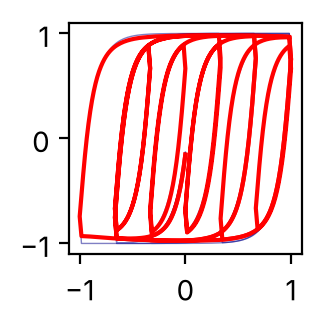

2701  --  0.004176821
2702  --  0.004173501
2703  --  0.0041774777
2704  --  0.0041886135
2705  --  0.004205497
2706  --  0.004225401
2707  --  0.0042451466


2708  --  0.004260743
2709  --  0.004267959
2710  --  0.0042645684


2711  --  0.0042507676
2712  --  0.004229166
2713  --  0.004203768
2714  --  0.004178407
2715  --  0.0041571213
2716  --  0.0041432967
2717  --  0.00413778


2718  --  0.004139808
2719  --  0.0041475403
2720  --  0.004158746


2721  --  0.0041702795
2722  --  0.004178999
2723  --  0.004182656
2724  --  0.004180096
2725  --  0.004171461
2726  --  0.004158084
2727  --  0.0041422355


2728  --  0.004126617
2729  --  0.004113894
2730  --  0.004106397


2731  --  0.0041060676
2732  --  0.0041132155
2733  --  0.004127207
2734  --  0.0041458076
2735  --  0.004166158
2736  --  0.004183393
2737  --  0.0041937088


2738  --  0.004194036
2739  --  0.0041836863
2740  --  0.0041646007


2741  --  0.0041402527
2742  --  0.004114847
2743  --  0.0040927827
2744  --  0.004077183
2745  --  0.0040696454
2746  --  0.0040698606
2747  --  0.004076447


2748  --  0.004086757
2749  --  0.0040978887


2750  --  0.0041069565


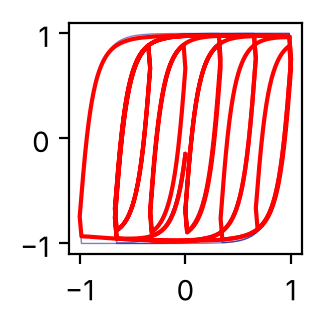

2751  --  0.0041115815
2752  --  0.00411047
2753  --  0.004103409
2754  --  0.0040916516


2755  --  0.0040770625
2756  --  0.004062138


2757  --  0.0040494404
2758  --  0.004041056
2759  --  0.0040387413
2760  --  0.004043246


2761  --  0.0040541324
2762  --  0.0040694256
2763  --  0.0040864493
2764  --  0.004101364


2765  --  0.0041107177
2766  --  0.0041118874


2767  --  0.004104177
2768  --  0.0040887985
2769  --  0.004068632
2770  --  0.0040473207


... (5 outputs left out)

2787  --  0.003978786
2788  --  0.0039808154
2789  --  0.0039887293
2790  --  0.004001632


2791  --  0.004016585
2792  --  0.0040309173
2793  --  0.00404121
2794  --  0.004044828
2795  --  0.004040419
2796  --  0.004028398


2797  --  0.004010886


2798  --  0.0039910697
2799  --  0.0039720642
2800  --  0.003957179


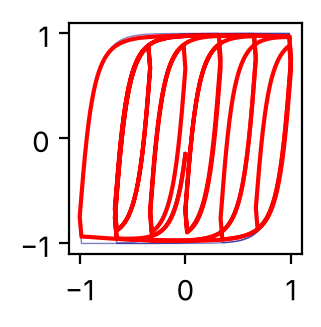

2801  --  0.0039485334
2802  --  0.003946872


2803  --  0.003951453


2804  --  0.0039607314
2805  --  0.0039723176
2806  --  0.0039837086
2807  --  0.003992056
2808  --  0.0039954996
2809  --  0.0039930367


2810  --  0.0039849915
2811  --  0.0039725704
2812  --  0.0039576897


2813

  --  0.0039427215
2814  --  0.0039302167
2815  --  0.003922452
2816  --  0.003920798
2817  --  0.003925539
2818  --  0.0039361576


... (2 outputs left out)

2829  --  0.0038926566
2830  --  0.0038891227
2831  --  0.0038930438
2832  --  0.0039033704


2833  --  0.0039177965
2834  --  0.0039332295
2835  --  0.0039464156
2836  --  0.0039545805
2837  --  0.003955932
2838  --  0.003950011
2839  --  0.0039376486


2840  --  0.0039207996
2841  --  0.0039022071
2842  --  0.003884975
2843  --  0.0038720432
2844  --  0.0038655412


2845  --  0.003866537
2846  --  0.0038749387
2847  --  0.003889567
2848  --  0.003907059
2849  --  0.00392386
2850  --  0.003935819


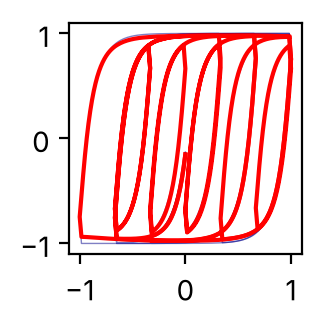

2851  --  0.0039396137
2852  --  0.003933816
2853  --  0.0039185886


2854  --  0.003897083
2855  --  0.0038737613
2856  --  0.0038529835
2857  --  0.0038384611
2858  --  0.003832803
2859  --  0.0038367163
2860  --  0.0038490272
2861  --  0.0038672674


2862  --  0.0038878797
2863  --  0.0039068484
2864  --  0.0039203004
2865  --  0.0039256085


2866  --  0.003921629
2867  --  0.0039089234
2868  --  0.003889645
2869  --  0.0038669996
2870  --  0.0038447953
2871  --  0.0038266883
2872  --  0.0038155064
2873  --  0.003812688


2874  --  0.0038186137
2875  --  0.00383188
2876  --  0.0038492195


2877  --  0.0038669584
2878  --  0.0038804463
2879  --  0.0038858873
2880  --  0.0038814736
2881  --  0.0038675347
2882  --  0.0038467764
2883  --  0.0038235167


2884  --  0.0038027316
2885  --  0.0037879075


2886  --  0.00378193
2887  --  0.0037857897
2888  --  0.0037984238
2889  --  0.003817434
2890  --  0.0038391438


2891  --  0.0038596033
2892  --  0.0038749382
2893  --  0.0038820314
2894  --  0.0038794721
2895  --  0.0038676967


2896  --  0.0038486978
2897  --  0.0038256892
2898  --  0.003802446
2899  --  0.0037826386
2900  --  0.0037692657


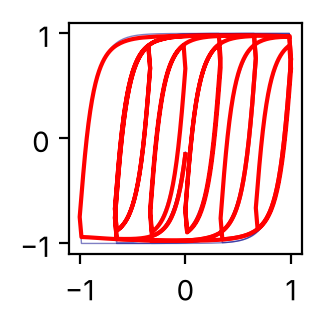

2901  --  0.0037642063
2902  --  0.0037676215
2903  --  0.0037785508
2904  --  0.0037941355


2905  --  0.0038104588
2906  --  0.0038238205
2907  --  0.003830161
2908  --  0.0038271497
2909  --  0.003814717
2910  --  0.0037954228
2911  --  0.0037732264
2912  --  0.00375264


2913  --  0.0037379
2914  --  0.0037319346
2915  --  0.0037354813
2916  --  0.0037477633


2917  --  0.0037666229
2918  --  0.0037887362
2919  --  0.0038099592
2920  --  0.0038264676
2921  --  0.0038351452
2922  --  0.003834367
2923  --  0.003824196


2924  --  0.003806415
2925  --  0.0037841073
2926  --  0.0037608217
2927  --  0.0037402299


2928  --  0.0037254165
2929  --  0.0037185666
2930  --  0.0037200681
2931  --  0.0037291464
2932  --  0.0037433463
2933  --  0.0037589767
2934  --  0.0037717244


2935  --  0.0037780802
2936  --  0.0037763787
2937  --  0.0037655728


2938  --  0.0037475366
2939  --  0.0037262498
2940  --  0.0037064515
2941  --  0.0036920593
2942  --  0.003686063
2943  --  0.0036896276
2944  --  0.0037021337


2945  --  0.003721616
2946  --  0.0037445845
2947  --  0.0037669481


2948  --  0.0037849154
2949  --  0.0037950836
2950  --  0.0037956706


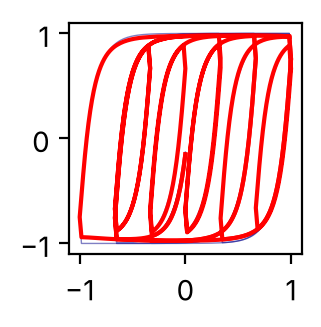

2951  --  0.0037865061
2952  --  0.0037691887
2953  --  0.0037466837


2954  --  0.0037226023
2955  --  0.003700776
2956  --  0.0036843596
2957  --  0.0036756746
2958  --  0.0036755144
2959  --  0.0036833188
2960  --  0.0036967234


2961  --  0.0037121545
2962  --  0.0037255331
2963  --  0.0037329763


2964  --  0.0037317155
2965  --  0.0037212763
2966  --  0.0037034482
2967  --  0.0036820876
2968  --  0.0036616437
2969  --  0.0036465316
2970  --  0.0036402026
2971  --  0.0036441013


2972  --  0.0036579354
2973  --  0.0036796376
2974  --  0.0037056697


2975  --  0.003731621
2976  --  0.003753159
2977  --  0.0037662683
2978  --  0.0037685467
2979  --  0.0037594507
2980  --  0.0037406185
2981  --  0.0037154313
2982  --  0.0036881645


2983  --  0.0036631015
2984  --  0.003643968
2985  --  0.0036332873


2986  --  0.0036320293
2987  --  0.0036396103
2988  --  0.0036536078
2989  --  0.0036700813
2990  --  0.0036839226
2991  --  0.0036911962
2992  --  0.0036890341
2993  --  0.00367711


2994  --  0.0036577082
2995  --  0.0036352985
2996  --  0.0036148299


2997  --  0.003600683
2998  --  0.003596125
2999  --  0.0036025608
3000  --  0.0036193493


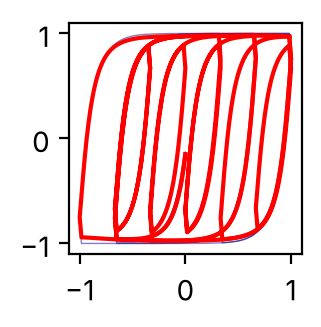

3001  --  0.0036440776


3002  --  0.0036727157
3003  --  0.00370048
3004  --  0.0037226581


3005  --  0.003734966
3006  --  0.0037354503
3007  --  0.0037240435
3008  --  0.003702892
3009  --  0.003675823
3010  --  0.00364748


3011  --  0.0036220977


3012  --  0.0036032791
3013  --  0.0035935058


3014  --  0.003593119
3015  --  0.0036010954
3016  --  0.0036144205
3017  --  0.0036290623
3018  --  0.0036405069
3019  --  0.0036449237
3020  --  0.0036402051


... (5 outputs left out)

3035  --  0.0036779188
3036  --  0.0036576407
3037  --  0.003632194
3038  --  0.003605735
3039  --  0.0035821777
3040  --  0.0035648472
3041  --  0.003555827


3042  --  0.003555518


3043  --  0.0035626886
3044  --  0.0035745148
3045  --  0.0035869065


3046  --  0.0035959478
3047  --  0.003598334
3048  --  0.0035925296
3049  --  0.0035791593
3050  --  0.0035608187


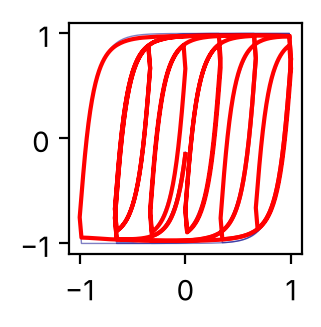

3051  --  0.003541513
3052  --  0.0035253009


3053  --  0.0035157767
3054  --  0.0035154934
3055  --  0.003525164
3056  --  0.0035437467
3057  --  0.0035688789
3058  --  0.0035969343
3059  --  0.0036235848
3060  --  0.0036444706
3061  --  0.0036559568


3062  --  0.0036561186
3063  --  0.003645002


3064  --  0.0036247058
3065  --  0.0035988628
3066  --  0.0035716703
3067  --  0.0035473863
3068  --  0.0035294956
3069  --  0.003520038
3070  --  0.0035194936
3071  --  0.0035266331


3072  --  0.0035385573
3073  --  0.0035511646


3074  --  0.0035601638
3075  --  0.0035622534
3076  --  0.0035557065
3077  --  0.0035411308
3078  --  0.0035214813
3079  --  0.0035008502
3080  --  0.003483925
3081  --  0.0034744807
3082  --  0.0034748004


3083  --  0.003485669
3084  --  0.003505973
3085  --  0.0035332395


3086  --  0.0035635743
3087  --  0.0035924762
3088  --  0.0036153244
3089  --  0.003628183
3090  --  0.0036289336
3091  --  0.003617569
3092  --  0.0035962833
3093  --  0.0035688851


3094  --  0.003540097
3095  --  0.0035143902
3096  --  0.003495392


3097  --  0.003485355
3098  --  0.0034848722
3099  --  0.0034925388
3100  --  0.0035051194


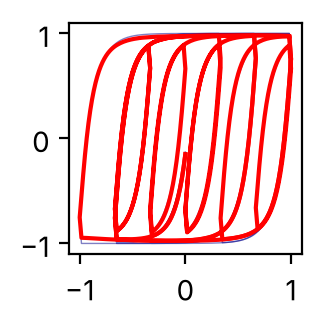

3101  --  0.0035182543
3102  --  0.0035273032
3103  --  0.0035286043
3104  --  0.0035205267


3105  --  0.003504137
3106  --  0.0034826545
3107  --  0.0034606047
3108  --  0.0034428155
3109  --  0.003433385
3110  --  0.003434739
3111  --  0.0034474714


3112  --  0.0034704143
3113  --  0.003500676
3114  --  0.0035339703


3115  --  0.0035653443
3116  --  0.003589789
3117  --  0.003603562
3118  --  0.00360407
3119  --  0.0035914718
3120  --  0.003568478
3121  --  0.003539347


3122  --  0.003509029
3123  --  0.003482223


3124  --  0.0034625768
3125  --  0.0034523767
3126  --  0.00345194
3127  --  0.0034595134
3128  --  0.0034716194
3129  --  0.0034837367
3130  --  0.0034910138
3131  --  0.0034900755


3132  --  0.0034797706
3133  --  0.0034615665


3134  --  0.0034390874
3135  --  0.0034171974
3136  --  0.0034006485
3137  --  0.0033932468
3138  --  0.0033971549
3139  --  0.0034127203
3140  --  0.0034385452
3141  --  0.0034713447


3142  --  0.0035066276
3143  --  0.0035391995


3144  --  0.003563858
3145  --  0.0035768738
3146  --  0.0035761856
3147  --  0.003562362
3148  --  0.0035382125
3149  --  0.0035081704
3150  --  0.003477329


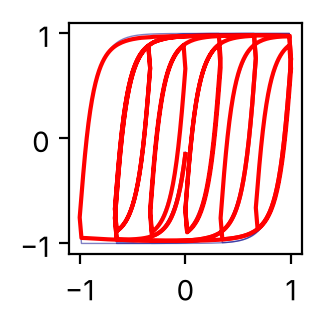

3151  --  0.0034503161
3152  --  0.0034306406


3153  --  0.0034203422
3154  --  0.003419534
3155  --  0.0034262217
3156  --  0.0034368702
3157  --  0.0034469033
3158  --  0.003451782
3159  --  0.0034485145
3160  --  0.0034367265
3161  --  0.0034181573


3162  --  0.003396061
3163  --  0.0033750744


3164  --  0.0033597492
3165  --  0.0033537785
3166  --  0.0033591338
3167  --  0.003376207
3168  --  0.0034034746
3169  --  0.0034377906
3170  --  0.0034746295
3171  --  0.0035087818


3172  --  0.0035351783
3173  --  0.0035497406


3174  --  0.0035503875
3175  --  0.0035375084
3176  --  0.0035137574
3177  --  0.0034835602
3178  --  0.003451982
3179  --  0.003423773
3180  --  0.0034025752
3181  --  0.003390538


3182  --  0.0033878495


3183  --  0.0033927348
3184  --  0.0034017956
3185  --  0.0034104302
3186  --  0.003414192
3187  --  0.003410381
3188  --  0.0033983267
3189  --  0.003379516
3190  --  0.0033574842


3191  --  0.0033363851
3192  --  0.0033209166


3193  --  0.0033147573
3194  --  0.0033201464
3195  --  0.0033375164
3196  --  0.0033655835
3197  --  0.0034014136
3198  --  0.0034406688
3199  --  0.0034781327


3200  --  0.0035083855


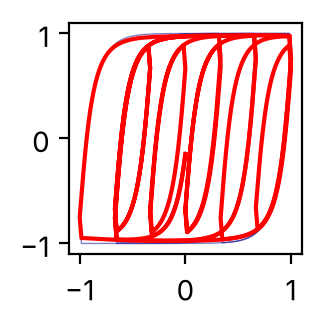

3201  --  0.003526888
3202  --  0.003530936
3203  --  0.0035204706
3204  --  0.003497764
3205  --  0.0034671605
3206  --  0.0034339118


3207  --  0.003403033
3208  --  0.0033786288
3209  --  0.0033632899
3210  --  0.0033575818


3211  --  0.003360043
3212  --  0.0033674235
3213  --  0.003375211
3214  --  0.0033789645
3215  --  0.0033757281
3216  --  0.0033640747


3217  --  0.0033450052
3218  --  0.0033220695
3219  --  0.0032995306
3220  --  0.0032820823


3221  --  0.003273719
3222  --  0.0032767858
3223  --  0.0032922626
3224  --  0.0033194982
3225  --  0.0033559317
3226  --  0.003397549


3227  --  0.00343929
3228  --  0.0034754542
3229  --  0.0035007312
3230  --  0.003511452


3231  --  0.003506441
3232  --  0.003487326
3233  --  0.0034580186
3234  --  0.0034236216
3235  --  0.0033896598
3236  --  0.003360893


3237  --  0.0033404857
3238  --  0.003329753
3239  --  0.003327897
3240  --  0.0033322445
3241  --  0.0033386555


3242  --  0.0033426841
3243  --  0.0033405689
3244  --  0.0033304133
3245  --  0.0033127775
3246  --  0.0032903922
3247  --  0.003267113
3248  --  0.0032474936
3249  --  0.0032355888


3250  --  0.0032344684


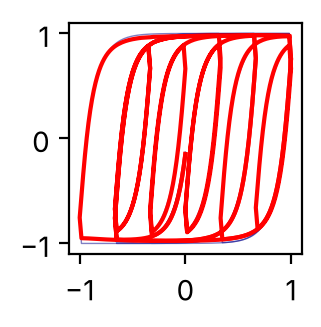

3251

  --  0.0032456461
3252  --  0.0032691318
3253  --  0.0033032158
3254  --  0.0033446786
3255  --  0.0033888186
3256  --  0.0034302033
3257  --  0.0034630217


3258  --  0.0034827944
3259  --  0.0034869867


3260  --  0.0034757138
3261  --  0.0034514284
3262  --  0.0034188505
3263  --  0.0033836206
3264  --  0.0033509915
3265  --  0.0033250835
3266  --  0.0033082315
3267  --  0.0033005867


3268  --  0.0033003904
3269  --  0.0033042238


3270  --  0.0033076266
3271  --  0.0033064205
3272  --  0.003298502
3273  --  0.003282911
3274  --  0.0032615447
3275  --  0.0032375276
3276  --  0.0032153027


3277  --  0.0031992372
3278  --  0.0031926148


3279  --  0.0031975517
3280  --  0.003214731
3281  --  0.003243411
3282  --  0.0032814166
3283  --  0.0033252486
3284  --  0.0033700443
3285  --  0.0034105084
3286  --  0.003441282


3287  --  0.0034584047
3288  --  0.0034598447
3289  --  0.003446309


3290  --  0.0034208419
3291  --  0.003388293
3292  --  0.0033539585
3293  --  0.0033227673
3294  --  0.0032983872
3295  --  0.0032825961
3296  --  0.003275123
3297  --  0.0032738906
3298  --  0.0032753295
3299  --  0.0032752142


3300  --  0.003270141


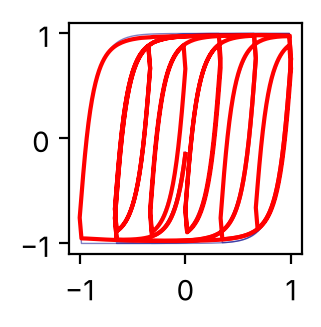

3301  --  0.0032582332
3302  --  0.0032396293
3303  --  0.0032165225
3304  --  0.003192373
3305  --  0.0031713904
3306  --  0.003157472
3307  --  0.003153437
3308  --  0.003160998
3309  --  0.0031805502


3310  --  0.0032112473
3311  --  0.0032509505
3312  --  0.0032961674


3313  --  0.0033422364
3314  --  0.0033838362
3315  --  0.0034158267
3316  --  0.0034343111
3317  --  0.0034373202
3318  --  0.0034253877
3319  --  0.003401344
3320  --  0.003369799
3321  --  0.0033359423
3322  --  0.0033046564


3323  --  0.003279554
3324  --  0.0032624677
3325  --  0.0032532206


3326  --  0.0032497523
3327  --  0.003248796
3328  --  0.003246387
3329  --  0.0032391844
3330  --  0.0032251428
3331  --  0.0032047636
3332  --  0.0031801492
3333  --  0.003154907
3334  --  0.003132941
3335  --  0.0031176785
3336  --  0.0031118537


3337  --  0.0031171087
3338  --  0.0031341126
3339  --  0.003162465
3340  --  0.003200538


3341  --  0.0032454226
3342  --  0.003292988
3343  --  0.003338487
3344  --  0.0033767915
3345  --  0.0034035596
3346  --  0.0034157769
3347  --  0.003412896
3348  --  0.0033963828
3349  --  0.0033698361
3350  --  0.0033379102


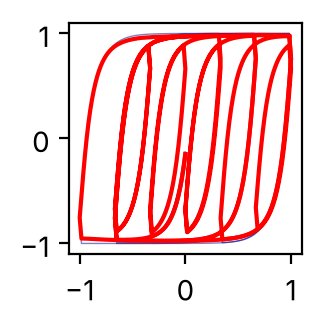

3351  --  0.003305518


3352  --  0.0032768743
3353  --  0.0032546963
3354  --  0.0032397604
3355  --  0.0032310367
3356  --  0.003226094
3357  --  0.003221146
3358  --  0.003212788
3359  --  0.0031986241
3360  --  0.0031787509
3361  --  0.003154396


3362  --  0.003128542


3363  --  0.0031045557
3364  --  0.0030857408
3365  --  0.0030747396
3366  --  0.0030734255
3367  --  0.0030828216
3368  --  0.0031030383
3369  --  0.0031334471
3370  --  0.0031723175
3371  --  0.003216691
3372  --  0.0032628255
3373  --  0.0033064743


3374  --  0.0033433575
3375  --  0.0033696638


3376  --  0.0033829948
3377  --  0.003382722
3378  --  0.0033699817
3379  --  0.0033477794
3380  --  0.0033199608
3381  --  0.003290617
3382  --  0.0032633545
3383  --  0.0032406908
3384  --  0.003223495
3385  --  0.003210815
3386  --  0.0032007776


3387  --  0.0031903025
3388  --  0.0031766726


3389  --  0.0031589204
3390  --  0.003137102
3391  --  0.0031126477
3392  --  0.0030880217
3393  --  0.0030657288
3394  --  0.0030481457
3395  --  0.00303733
3396  --  0.003034659
3397  --  0.0030409961
3398  --  0.0030566514
3399  --  0.0030813187


3400  --  0.003113967


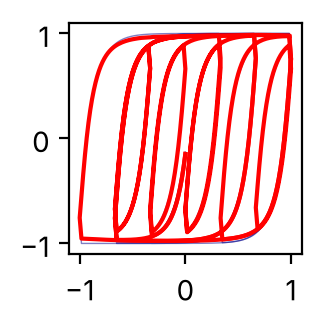

3401  --  0.0031527
3402  --  0.0031948637
3403  --  0.0032374065
3404  --  0.0032770704
3405  --  0.003310464
3406  --  0.0033349344
3407  --  0.0033486167
3408  --  0.0033508858
3409  --  0.0033424858


3410  --  0.0033254293
3411  --  0.0033024652
3412  --  0.0032767635


3413  --  0.0032511828
3414  --  0.0032277796
3415  --  0.003207657
3416  --  0.00319027
3417  --  0.0031738882
3418  --  0.0031568187
3419  --  0.0031379224
3420  --  0.0031165662
3421  --  0.0030931043
3422  --  0.0030689726


3423  --  0.0030458842
3424  --  0.0030256957


3425  --  0.0030099528
3426  --  0.0029999758
3427  --  0.0029967108
3428  --  0.0030007192
3429  --  0.0030122683
3430  --  0.0030313241
3431  --  0.0030573066
3432  --  0.0030892203
3433  --  0.0031254196
3434  --  0.0031641219
3435  --  0.0032032423


3436  --  0.003240349
3437  --  0.0032731516


3438  --  0.0032994421
3439  --  0.003317442
3440  --  0.0033259967
3441  --  0.0033248686
3442  --  0.0033146709
3443  --  0.0032970882
3444  --  0.0032744193
3445  --  0.003249309
3446  --  0.0032238043
3447  --  0.0031991804


3448  --  0.0031758153
3449  --  0.0031531756


3450  --  0.003130357


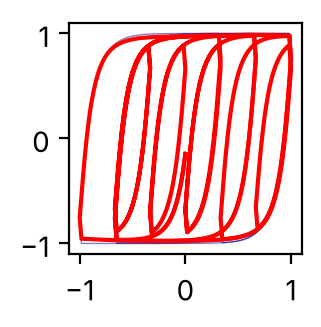

3451  --  0.0031068628
3452  --  0.003082468
3453  --  0.003057617
3454  --  0.0030333074
3455  --  0.0030107668
3456  --  0.00299116


3457  --  0.0029755246
3458  --  0.002964694
3459  --  0.0029591457


3460  --  0.0029591972
3461  --  0.0029650873
3462  --  0.002976863


3463  --  0.002994377
3464  --  0.0030170474
3465  --  0.00304419
3466  --  0.0030750458


3467  --  0.00310862
3468  --  0.0031440363
3469  --  0.003180234


3470  --  0.0032159828
3471  --  0.0032497048
3472  --  0.0032793994


... (3 outputs left out)

3484  --  0.0030879497
3485  --  0.0030588307
3486  --  0.0030316222
3487  --  0.0030067093
3488  --  0.0029845792


3489  --  0.0029657069
3490  --  0.0029502262
3491  --  0.0029381744


3492  --  0.0029295648
3493  --  0.002924283
3494  --  0.0029224048
3495  --  0.0029238972
3496  --  0.0029288875


3497  --  0.002937183
3498  --  0.0029486185
3499  --  0.002963
3500  --  0.0029801417


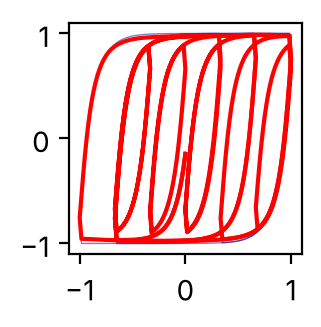

3501  --  0.003000075
3502  --  0.0030230498


3503  --  0.0030495145
3504  --  0.003079887
3505  --  0.0031144822
3506  --  0.0031531972
3507  --  0.003195152


3508  --  0.0032385697
3509  --  0.00328064
3510  --  0.0033177754
3511  --  0.0033459496
3512  --  0.0033614584
3513  --  0.0033619322
3514  --  0.0033461729


3515  --  0.0033156343
3516  --  0.003273959


3517  --  0.0032252586
3518  --  0.0031739387
3519  --  0.0031243316
3520  --  0.0030791254


3521  --  0.0030395607
3522  --  0.0030064362
3523  --  0.0029795656
3524  --  0.0029583296
3525  --  0.0029418743
3526  --  0.0029293539
3527  --  0.0029198793


... (2 outputs left out)

3534  --  0.00289505
3535  --  0.0028945801
3536  --  0.0028946898
3537  --  0.0028953275
3538  --  0.0028965175
3539  --  0.0028983965
3540  --  0.0029012184


3541  --  0.0029054591
3542  --  0.0029118564


3543  --  0.0029214693
3544  --  0.0029357472
3545  --  0.002956331
3546  --  0.0029852379


3547  --  0.0030247995
3548  --  0.0030770947
3549  --  0.0031436817
3550  --  0.003224842


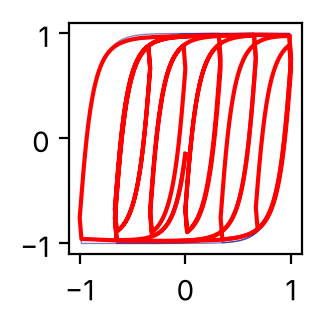

3551  --  0.0033184742


3552  --  0.0034191161
3553  --  0.0035171136
3554  --  0.003599263
3555  --  0.003650654


3556  --  0.0036595378
3557  --  0.0036207668
3558  --  0.003540072
3559  --  0.003431425
3560  --  0.0033123533
3561  --  0.003199951
3562  --  0.003106617


3563  --  0.0030396772


3564  --  0.0030012936
3565  --  0.002990643
3566  --  0.0030036366
3567  --  0.0030338455


3568  --  0.0030735335
3569  --  0.0031126733
3570  --  0.0031419194
3571  --  0.0031542964
3572  --  0.0031470489
3573  --  0.0031217607
3574  --  0.0030832498


... (4 outputs left out)

3588  --  0.003098331
3589  --  0.0030879662
3590  --  0.0030771792
3591  --  0.0030663258


3592  --  0.0030554552
3593  --  0.0030445743
3594  --  0.0030334615
3595  --  0.0030213995
3596  --  0.003007424
3597  --  0.0029905282


3598  --  0.0029706284


3599  --  0.0029478488
3600  --  0.0029234535


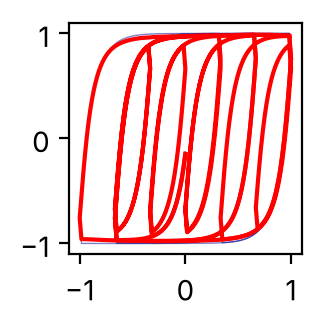

3601  --  0.002899179
3602  --  0.0028767989
3603  --  0.0028578527
3604  --  0.0028435404
3605  --  0.002834617
3606  --  0.0028314048
3607  --  0.0028339413
3608  --  0.0028419448


3609  --  0.0028549454


3610  --  0.0028723746
3611  --  0.0028934826
3612  --  0.0029173864
3613  --  0.0029431225


3614  --  0.002969549
3615  --  0.0029954494
3616  --  0.0030195222
3617  --  0.0030403554
3618  --  0.0030566435
3619  --  0.0030672627
3620  --  0.0030713642
3621  --  0.0030685428
3622  --  0.0030590203


3623  --  0.0030435466


3624  --  0.0030233338
3625  --  0.0029999923
3626  --  0.0029750275


... (2 outputs left out)

3636  --  0.0028072493
3637  --  0.002800983
3638  --  0.0027960518


3639  --  0.0027922771
3640  --  0.0027894669
3641  --  0.0027874277
3642  --  0.002785999
3643  --  0.0027850722
3644  --  0.0027844892
3645  --  0.0027841548
3646  --  0.0027839642


3647  --  0.0027839136


3648  --  0.0027840857
3649  --  0.0027847493
3650  --  0.0027863062


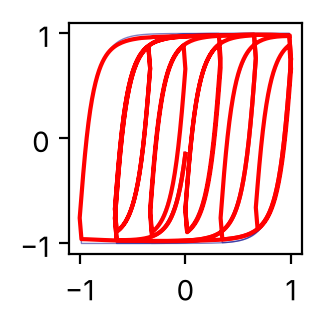

3651  --  0.002789364
3652  --  0.0027947335
3653  --  0.002803503
3654  --  0.0028170599
3655  --  0.0028372048


3656  --  0.002866122


3657  --  0.0029065309
3658  --  0.0029614838
3659  --  0.003034122
3660  --  0.0031269407
3661  --  0.003240433
3662  --  0.0033707395


3663  --  0.0035077608
3664  --  0.0036337858
3665  --  0.003725102
3666  --  0.003758948
3667  --  0.003722303


3668  --  0.0036183845
3669  --  0.0034671025
3670  --  0.0032971925
3671  --  0.003136088
3672  --  0.0030035197
3673  --  0.0029101914
3674  --  0.0028592201


3675  --  0.0028489984
3676  --  0.0028744591
3677  --  0.0029279108
3678  --  0.0029972435
3679  --  0.0030667265


3680  --  0.0031196214
3681  --  0.0031435234
3682  --  0.003134032
3683  --  0.00309623
3684  --  0.0030404278
3685  --  0.0029784297


3686  --  0.0029212164
3687  --  0.00287806
3688  --  0.0028553526
3689  --  0.0028546616


3690  --  0.002872135
3691  --  0.0028990216
3692  --  0.0029245247
3693  --  0.002939137
3694  --  0.0029381255
3695  --  0.0029224753
3696  --  0.0028978938


3697  --  0.0028711057
3698  --  0.0028477989
3699  --  0.002830787


3700  --  0.0028208753


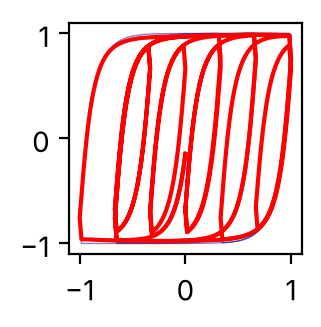

3701  --  0.0028172296
3702  --  0.0028182215


3703  --  0.0028215833
3704  --  0.0028247256
3705  --  0.002825363
3706  --  0.0028220124
3707  --  0.002814394


3708  --  0.0028030756
3709  --  0.0027896275
3710  --  0.0027761147
3711  --  0.0027645533
3712  --  0.0027566534


3713  --  0.0027536105
3714  --  0.0027561272
3715  --  0.002764393


3716  --  0.0027781636
3717  --  0.002796803
3718  --  0.0028193404
3719  --  0.0028444978
3720  --  0.0028708836


3721  --  0.002896769
3722  --  0.0029204106
3723  --  0.0029402315
3724  --  0.0029548255
3725  --  0.0029631604


... (4 outputs left out)

3738  --  0.0027472014
3739  --  0.002734509
3740  --  0.0027237097
3741  --  0.002714748


3742  --  0.0027075203
3743  --  0.0027019097
3744  --  0.0026977868
3745  --  0.0026949851


3746  --  0.0026933255


3747  --  0.002692623
3748  --  0.0026926277
3749  --  0.002693088
3750  --  0.0026937232


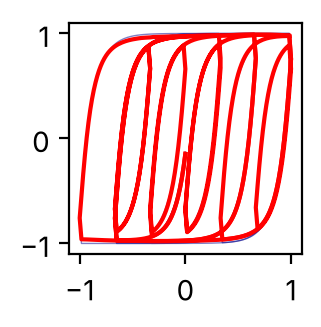

3751  --  0.002694273
3752  --  0.0026945004


3753  --  0.0026942706


3754  --  0.0026935472
3755  --  0.0026924063
3756  --  0.0026910605
3757  --  0.0026898594
3758  --  0.002689267
3759  --  0.0026898785


3760  --  0.002692386
3761  --  0.0026976054


3762  --  0.002706487


3763  --  0.0027202277
3764  --  0.002740303
3765  --  0.002768682
3766  --  0.0028078437
3767  --  0.0028607124
3768  --  0.0029306146


... (5 outputs left out)

3783  --  0.0027484626
3784  --  0.0027226282
3785  --  0.002735998
3786  --  0.002783
3787  --  0.0028541887
3788  --  0.0029352452
3789  --  0.0030072548


3790  --  0.00305244
3791  --  0.0030603206
3792  --  0.0030321118


3793  --  0.0029776648
3794  --  0.0029115744
3795  --  0.0028481795
3796  --  0.0027988143
3797  --  0.0027713883


3798  --  0.0027689335
3799  --  0.0027879619
3800  --  0.002818862


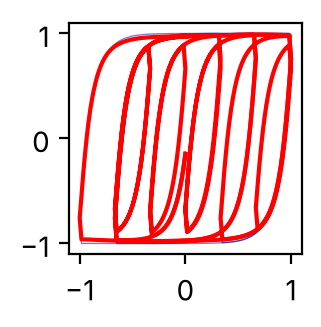

3801  --  0.0028482727
3802  --  0.0028633126


3803  --  0.0028575447
3804  --  0.002832289
3805  --  0.0027954453
3806  --  0.0027568203
3807  --  0.0027239963


3808  --  0.0027011828
3809  --  0.002689142
3810  --  0.0026863837
3811  --  0.0026901679
3812  --  0.002697057
3813  --  0.002703624


3814  --  0.0027071082
3815  --  0.0027060194


3816  --  0.0027000995
3817  --  0.0026904782
3818  --  0.0026791412
3819  --  0.0026684874
3820  --  0.0026607171


3821  --  0.0026574496
3822  --  0.0026596675
3823  --  0.0026677423
3824  --  0.0026814954
3825  --  0.0027002543
3826  --  0.0027229434


... (2 outputs left out)

3834  --  0.0028628604
3835  --  0.0028568541
3836  --  0.002845026
3837  --  0.0028284995
3838  --  0.002808631
3839  --  0.002786815


3840  --  0.002764197
3841  --  0.0027417722


3842  --  0.0027202836
3843  --  0.0027002248
3844  --  0.0026818812
3845  --  0.0026652135
3846  --  0.0026503876


3847  --  0.002637457
3848  --  0.0026264926
3849  --  0.0026175145
3850  --  0.002610475


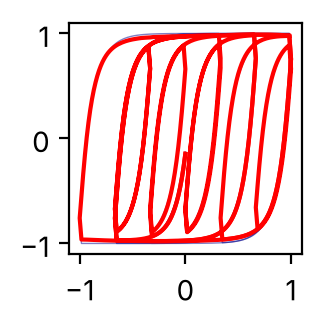

3851  --  0.0026052874
3852  --  0.002601749


3853  --  0.0025996258
3854  --  0.002598654
3855  --  0.0025985169
3856  --  0.002598911


3857  --  0.002599514
3858  --  0.0026000314
3859  --  0.0026002158
3860  --  0.002599892
3861  --  0.0025989558
3862  --  0.0025974296
3863  --  0.0025954146


3864  --  0.0025930952
3865  --  0.0025906954


3866  --  0.002588465
3867  --  0.0025866604
3868  --  0.0025855303


3869  --  0.0025853233
3870  --  0.0025862986
3871  --  0.0025887925
3872  --  0.0025932733
3873  --  0.0026004727
3874  --  0.0026114804
3875  --  0.0026279618


... (4 outputs left out)

3890  --  0.0031385075
3891  --  0.0029210073


3892  --  0.002763978
3893  --  0.0026740644
3894  --  0.0026460025
3895  --  0.0026684827
3896  --  0.0027266748
3897  --  0.0028018982


3898  --  0.002872956
3899  --  0.0029187715


3900  --  0.0029270821


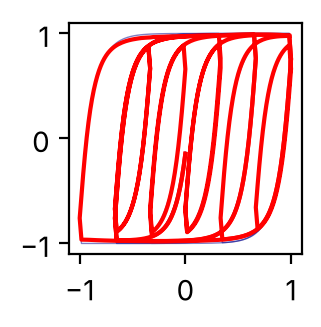

3901  --  0.0028990486
3902  --  0.0028462762
3903  --  0.0027845637
3904  --  0.002727981


3905  --  0.0026862032
3906  --  0.0026649279
3907  --  0.002665393
3908  --  0.0026846062


3909  --  0.0027142032
3910  --  0.0027415424
3911  --  0.0027542047


3912  --  0.0027460842
3913  --  0.002718467
3914  --  0.002678729
3915  --  0.0026367153


3916  --  0.0026005383
3917  --  0.0025748
3918  --  0.0025605273
3919  --  0.0025563587


3920  --  0.0025594742
3921  --  0.002566367
3922  --  0.0025736294
3923  --  0.0025785188


... (4 outputs left out)

3938  --  0.0027023407
3939  --  0.0027251688
3940  --  0.0027441252
3941  --  0.0027581558
3942  --  0.002766552


3943  --  0.0027689275
3944  --  0.0027653235
3945  --  0.0027562354
3946  --  0.0027425084


3947  --  0.0027251139
3948  --  0.0027052094
3949  --  0.0026838582


3950  --  0.0026619853


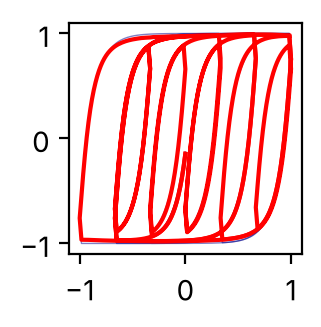

3951  --  0.002640233
3952  --  0.0026192418


3953  --  0.002599442
3954  --  0.0025812103
3955  --  0.0025648817


3956  --  0.0025506509
3957  --  0.0025386885
3958  --  0.0025290682


3959  --  0.00252173
3960  --  0.0025165083
3961  --  0.002513148


3962  --  0.002511307
3963  --  0.0025105996


3964  --  0.002510649
3965  --  0.0025110384


... (10 outputs left out)

3991  --  0.0025627695


3992  --  0.0026229064
3993  --  0.002716536
3994  --  0.0028559484
3995  --  0.0030528277
3996  --  0.0033106438


3997  --  0.0036111996
3998  --  0.0039004546


3999  --  0.0040912144
4000  --  0.0041000806


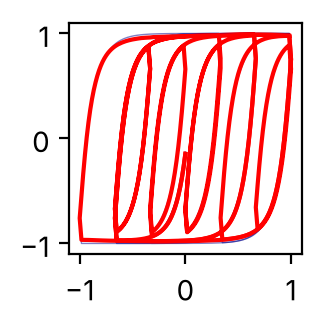

4001  --  0.0039062756
4002  --  0.0035747634
4003  --  0.0032152275
4004  --  0.0029193482


4005  --  0.0027311847
4006  --  0.0026511536


4007  --  0.002653999
4008  --  0.0027036343
4009  --  0.0027614003
4010  --  0.0027962164


4011  --  0.0027926823
4012  --  0.0027530526
4013  --  0.0026934762
4014  --  0.0026323663


4015  --  0.0025835913
4016  --  0.0025541426


4017  --  0.0025446557
4018  --  0.002552318
4019  --  0.002572082
4020  --  0.002597241


... (5 outputs left out)

4039  --  0.002448656
4040  --  0.0024452237
4041  --  0.0024451087


4042  --  0.0024491071
4043  --  0.002457497
4044  --  0.0024700668
4045  --  0.0024862161


4046  --  0.0025049846
4047  --  0.002525319
4048  --  0.0025461463
4049  --  0.0025664193


4050  --  0.0025851775


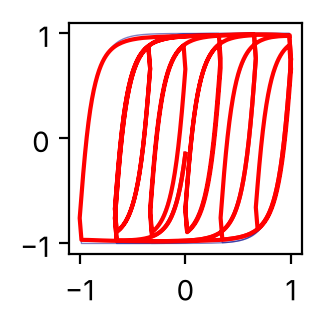

4051  --  0.0026016713
4052  --  0.0026154302
4053  --  0.0026260342


4054  --  0.0026331681
4055  --  0.002636704
4056  --  0.0026365595
4057  --  0.002632812
4058  --  0.0026256759
4059  --  0.0026153699


4060  --  0.002602358
4061  --  0.0025872467
4062  --  0.0025706918


4063  --  0.0025531102
4064  --  0.0025351595
4065  --  0.002517623


4066  --  0.0025011417
4067  --  0.0024861847
4068  --  0.002473103
4069  --  0.0024621026
4070  --  0.00245321


4071  --  0.002446272
4072  --  0.0024410356
4073  --  0.0024371848


... (4 outputs left out)

4088  --  0.002404315
4089  --  0.00240377
4090  --  0.0024035226
4091  --  0.0024034274
4092  --  0.0024033282
4093  --  0.0024030877


4094  --  0.0024026062
4095  --  0.0024018437


4096  --  0.0024008336
4097  --  0.0023996944
4098  --  0.0023986339
4099  --  0.0023979463


4100  --  0.0023980143


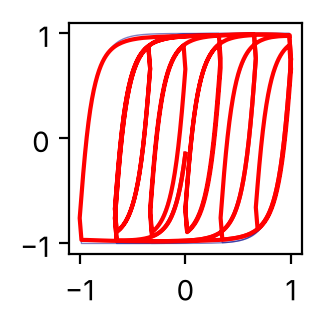

4101  --  0.0023993105
4102  --  0.0024024304


4103  --  0.0024081487
4104  --  0.0024175004


4105  --  0.0024321557
4106  --  0.0024543658
4107  --  0.002487668
4108  --  0.002537521


4109  --  0.0026121517
4110  --  0.0027225793
4111  --  0.0028816108


4112  --  0.0030992776
4113  --  0.0033720224


4114  --  0.0036666845
4115  --  0.00391121


... (9 outputs left out)

4142  --  0.0024188524
4143  --  0.0023929642
4144  --  0.0023737957
4145  --  0.0023624431


4146  --  0.002358322
4147  --  0.002359829


4148  --  0.0023646706


4149  --  0.0023703787
4150  --  0.0023746393


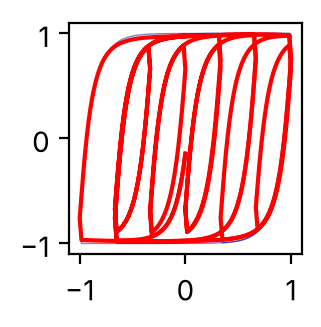

4151  --  0.002376061
4152  --  0.0023740886
4153  --  0.0023691677
4154  --  0.0023625547


4155  --  0.002355918
4156  --  0.0023510938


4157  --  0.0023497927


4158  --  0.0023532424
4159  --  0.0023621877
4160  --  0.0023768202
4161  --  0.002396706
4162  --  0.0024209837
4163  --  0.0024482496


4164  --  0.002476967
4165  --  0.00250537
4166  --  0.0025317236


4167  --  0.0025545324
4168  --  0.0025725353


... (6 outputs left out)

4190  --  0.0023307644
4191  --  0.0023339088
4192  --  0.0023375985


4193  --  0.0023409666


4194  --  0.0023433482


4195  --  0.002344209
4196  --  0.0023432705
4197  --  0.0023405736
4198  --  0.0023364397
4199  --  0.0023313914
4200  --  0.0023260913


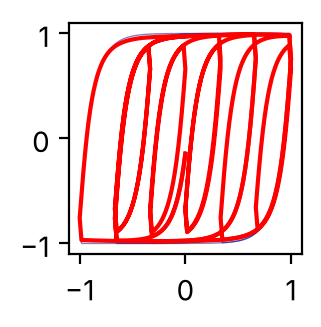

4201  --  0.002321183
4202  --  0.002317236


4203  --  0.0023146283


4204  --  0.0023135608
4205  --  0.002313972
4206  --  0.0023155843
4207  --  0.0023179848
4208  --  0.0023206177
4209  --  0.0023228733
4210  --  0.0023242077
4211  --  0.00232418


4212  --  0.002322559
4213  --  0.0023193923


4214  --  0.0023150728


4215  --  0.0023102441
4216  --  0.002305917
4217  --  0.002303439
4218  --  0.002304571
4219  --  0.0023114611
4220  --  0.0023269327
4221  --  0.0023548543


... (5 outputs left out)

4234  --  0.0029772224
4235  --  0.0027123983
4236  --  0.0025760327
4237  --  0.0025366868
4238  --  0.002543618
4239  --  0.0025528981
4240  --  0.0025408592
4241  --  0.0025051495


4242  --  0.0024564438


4243  --  0.002408752


4244  --  0.0023717931
4245  --  0.002349631
4246  --  0.0023414514
4247  --  0.0023436411
4248  --  0.0023518312
4249  --  0.002361356
4250  --  0.0023681512


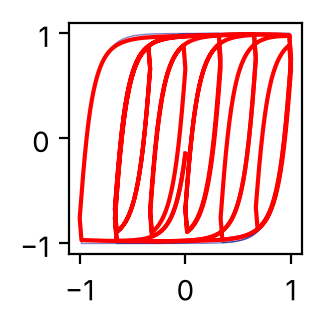

4251  --  0.002369626


4252  --  0.0023641952
4253  --  0.0023524791
4254  --  0.0023362855
4255  --  0.0023182668
4256  --  0.0023010985
4257  --  0.0022867655
4258  --  0.0022762981
4259  --  0.0022698645
4260  --  0.0022669577
4261  --  0.0022664901


4262  --  0.0022672797


4263  --  0.0022682082
4264  --  0.0022685272
4265  --  0.0022678238
4266  --  0.0022661889
4267  --  0.002264086
4268  --  0.002262174
4269  --  0.002261187
4270  --  0.002261798
4271  --  0.0022645078
4272  --  0.002269605
4273  --  0.00227709


4274  --  0.0022867366


4275  --  0.0022981882
4276  --  0.0023109256
4277  --  0.0023243935
4278  --  0.0023380166
4279  --  0.0023512684
4280  --  0.0023636485
4281  --  0.002374813
4282  --  0.0023844321
4283  --  0.0023922361
4284  --  0.0023979621


4285  --  0.0024014679


4286  --  0.0024026642
4287  --  0.0024015426
4288  --  0.0023981582
4289  --  0.0023926042
4290  --  0.0023850545
4291  --  0.0023757883
4292  --  0.0023650858
4293  --  0.0023534202
4294  --  0.0023412723
4295  --  0.0023291023
4296  --  0.0023173362
4297  --  0.0023063144


4298  --  0.002296289


4299  --  0.0022873993
4300  --  0.0022796807


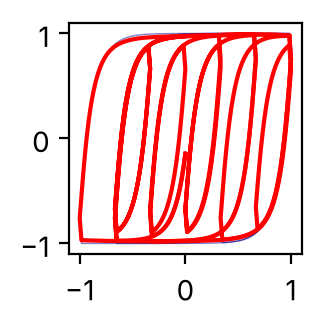

4301  --  0.0022731177
4302  --  0.002267584
4303  --  0.0022629257
4304  --  0.0022589674
4305  --  0.0022555385
4306  --  0.0022524432


4307  --  0.0022495154


4308  --  0.0022466371
4309  --  0.0022437326
4310  --  0.0022407784
4311  --  0.0022378028


4312  --  0.0022348766
4313  --  0.0022321085
4314  --  0.0022296102
4315  --  0.0022275099
4316  --  0.0022259287
4317  --  0.0022249664
4318  --  0.0022246807


4319  --  0.0022251166
4320  --  0.0022262905


4321  --  0.0022282165
4322  --  0.0022308964
4323  --  0.0022343525


... (3 outputs left out)

4335  --  0.0023875993
4336  --  0.002409392
4337  --  0.002429128
4338  --  0.0024452684
4339  --  0.0024565603
4340  --  0.0024622951


4341  --  0.0024625696
4342  --  0.0024581566
4343  --  0.00245035


4344  --  0.0024404917
4345  --  0.0024296783
4346  --  0.002418488


4347  --  0.002406919
4348  --  0.0023943142
4349  --  0.002379538
4350  --  0.0023612075


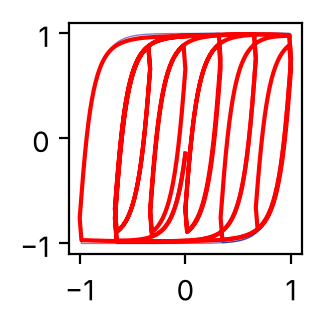

4351  --  0.0023381978
4352  --  0.0023100483
4353  --  0.0022775158


4354  --  0.0022432003
4355  --  0.0022121025


4356  --  0.0021923273
4357  --  0.0021963369
4358  --  0.0022422916
4359  --  0.0023559388
4360  --  0.0025702633


4361  --  0.0029173382
4362  --  0.003402795
4363  --  0.003956229


4364  --  0.0043953536
4365  --  0.004497633


4366  --  0.0041840523
4367  --  0.0036133162
4368  --  0.003038325
4369  --  0.002624217
4370  --  0.0024064295


... (4 outputs left out)

4387  --  0.0022229438
4388  --  0.0022187503


4389  --  0.0022103775
4390  --  0.0021999262
4391  --  0.0021893235
4392  --  0.002180147
4393  --  0.0021732769
4394  --  0.0021688452
4395  --  0.0021664524


4396  --  0.0021654412
4397  --  0.0021650842
4398  --  0.0021648186
4399  --  0.0021643508


4400  --  0.0021636412


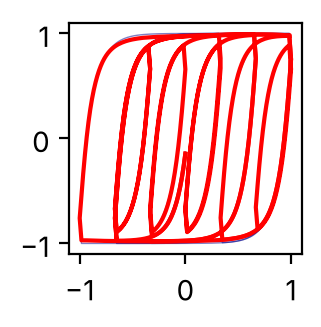

4401  --  0.0021628605
4402  --  0.0021622968
4403  --  0.0021622414
4404  --  0.002162961


4405  --  0.0021645783
4406  --  0.0021670952
4407  --  0.0021703844
4408  --  0.0021742042


4409  --  0.0021782944
4410  --  0.0021823563
4411  --  0.002186138
4412  --  0.002189455


4413  --  0.0021922137
4414  --  0.0021943676
4415  --  0.0021959879
4416  --  0.0021971595


4417  --  0.0021979788
4418  --  0.0021985336
4419  --  0.0021989043
4420  --  0.0021991516


4421  --  0.0021992924
4422  --  0.0021993287
4423  --  0.0021992729
4424  --  0.0021991327


... (3 outputs left out)

4438  --  0.0021991807
4439  --  0.0021988656
4440  --  0.002198296
4441  --  0.0021974635


4442  --  0.002196384
4443  --  0.002195089
4444  --  0.002193615
4445  --  0.002192012


4446  --  0.002190331
4447  --  0.0021886225
4448  --  0.0021869328
4449  --  0.002185314


4450  --  0.0021838073


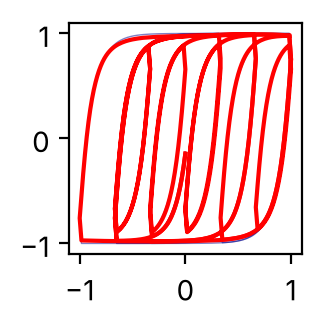

4451  --  0.0021824471
4452  --  0.0021812706


4453  --  0.0021803176
4454  --  0.0021796322
4455  --  0.002179257
4456  --  0.0021792478


4457  --  0.0021796613
4458  --  0.0021805528
4459  --  0.002181972
4460  --  0.002183966


4461  --  0.0021865766
4462  --  0.0021897953


4463  --  0.0021936016
4464  --  0.0021979287
4465  --  0.002202705
4466  --  0.0022078003


4467  --  0.002213063
4468  --  0.0022183429
4469  --  0.0022234763
4470  --  0.0022283075


... (5 outputs left out)

4487  --  0.0022232556
4488  --  0.0022115754
4489  --  0.0021983837
4490  --  0.002184689


4491  --  0.002171788


4492  --  0.002161126
4493  --  0.0021542031
4494  --  0.0021524585
4495  --  0.0021571617
4496  --  0.0021693562
4497  --  0.0021893696


4498  --  0.0022165077
4499  --  0.0022486246
4500  --  0.0022806586


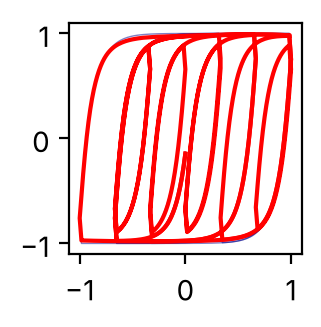

4501  --  0.0023046276


4502  --  0.0023117776
4503  --  0.00229683
4504  --  0.002260649
4505  --  0.0022110713
4506  --  0.0021602358
4507  --  0.0021208248
4508  --  0.0021032123


4509  --  0.0021161672
4510  --  0.0021662172
4511  --  0.002257559
4512  --  0.002390249
4513  --  0.0025586695


4514  --  0.00274838


4515  --  0.0029329949
4516  --  0.0030785953
4517  --  0.0031513122
4518  --  0.0031292017
4519  --  0.0030181012
4520  --  0.0028521426
4521  --  0.0026796649


4522  --  0.002540059
4523  --  0.0024488529
4524  --  0.0023975626
4525  --  0.002365756


... (5 outputs left out)

4540  --  0.0022278526
4541  --  0.0022049672
4542  --  0.0021845738
4543  --  0.0021672845


4544  --  0.0021530704


4545  --  0.0021415392
4546  --  0.002132035
4547  --  0.0021239321
4548  --  0.0021166552
4549  --  0.0021097434


4550  --  0.002102923


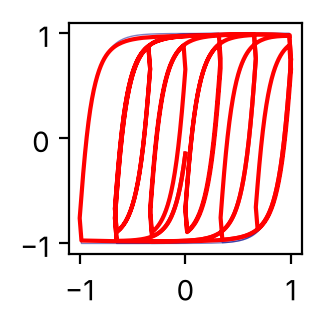

4551  --  0.0020961142


4552  --  0.0020893486
4553  --  0.0020827132
4554  --  0.0020763204
4555  --  0.0020702884
4556  --  0.0020647116
4557  --  0.002059646


4558  --  0.0020551162
4559  --  0.002051122
4560  --  0.0020476524
4561  --  0.0020446687


4562  --  0.00204214
4563  --  0.0020400353
4564  --  0.002038327
4565  --  0.00203699
4566  --  0.0020360088
4567  --  0.0020353345
4568  --  0.0020349442


4569  --  0.0020348132
4570  --  0.0020349193
4571  --  0.0020352514
4572  --  0.002035803


4573  --  0.0020365939
4574  --  0.0020376656
4575  --  0.0020390677
4576  --  0.0020408675
4577  --  0.002043156
4578  --  0.002046027
4579  --  0.0020495937
4580  --  0.0020539744


4581  --  0.0020593035
4582  --  0.002065729
4583  --  0.002073395
4584  --  0.002082463


4585  --  0.0020930734
4586  --  0.0021053355
4587  --  0.0021193
4588  --  0.002134932
4589  --  0.00215208
4590  --  0.0021704263
4591  --  0.0021894544


4592  --  0.0022084296
4593  --  0.0022264065


4594  --  0.00224221
4595  --  0.0022545964
4596  --  0.0022624678
4597  --  0.002264927
4598  --  0.002261425
4599  --  0.0022518975
4600  --  0.002236659


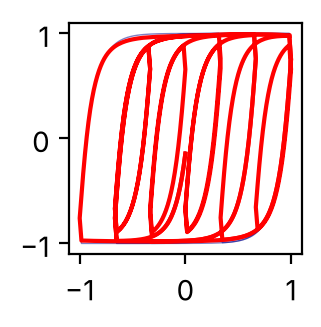

4601  --  0.0022166718
4602  --  0.0021931299
4603  --  0.0021675157
4604  --  0.002141206
4605  --  0.0021153975
4606  --  0.0020910986
4607  --  0.0020690593
4608  --  0.002049747
4609  --  0.0020334348
4610  --  0.002020267


4611  --  0.0020102852
4612  --  0.002003465
4613  --  0.0019998283
4614  --  0.0019994248
4615  --  0.002002344
4616  --  0.0020087573
4617  --  0.0020188603
4618  --  0.0020328055
4619  --  0.002050821


4620  --  0.0020728114
4621  --  0.0020983878
4622  --  0.0021267699
4623  --  0.0021568113
4624  --  0.002186796
4625  --  0.002214542
4626  --  0.0022376485
4627  --  0.0022538516
4628  --  0.0022614405
4629  --  0.0022595667


4630  --  0.0022484197
4631  --  0.0022292538
4632  --  0.002203873
4633  --  0.0021739278
4634  --  0.0021415767
4635  --  0.0021088824
4636  --  0.002076966
4637  --  0.0020471995
4638  --  0.0020206326
4639  --  0.0019984408
4640  --  0.0019823755
4641  --  0.0019748257


4642  --  0.0019793191
4643  --  0.0020005507
4644  --  0.0020443376
4645  --  0.0021172797
4646  --  0.0022255029
4647  --  0.0023717168
4648  --  0.0025504413
4649  --  0.0027419277
4650  --  0.0029103486


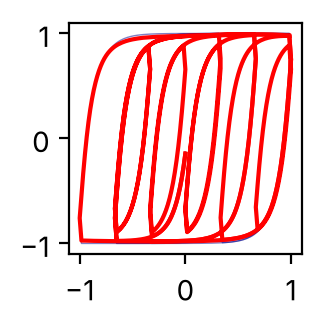

4651  --  0.003009575
4652  --  0.003004707
4653  --  0.0028922558
4654  --  0.0027068455
4655  --  0.0025022752
4656  --  0.002326746
4657  --  0.0022069996
4658  --  0.0021477293
4659  --  0.0021362035
4660  --  0.0021507447


4661  --  0.0021674172
4662  --  0.0021678733
4663  --  0.0021449851
4664  --  0.0021039904
4665  --  0.0020569817
4666  --  0.0020155131
4667  --  0.0019871267
4668  --  0.0019744725
4669  --  0.0019768993
4670  --  0.0019913649
4671  --  0.0020127615
4672  --  0.0020350586


4673  --  0.0020522408
4674  --  0.0020596744
4675  --  0.0020554785
4676  --  0.0020410279
4677  --  0.0020204065
4678  --  0.0019984308
4679  --  0.0019789194
4680  --  0.001964154
4681  --  0.001954829
4682  --  0.0019503252
4683  --  0.0019492368
4684  --  0.0019498633
4685  --  0.0019506778


4686  --  0.0019505854
4687  --  0.0019490884
4688  --  0.0019463543
4689  --  0.0019430459
4690  --  0.0019401165
4691  --  0.0019385364
4692  --  0.0019392272
4693  --  0.0019428636
4694  --  0.0019497677
4695  --  0.0019599113
4696  --  0.0019729105
4697  --  0.0019881525
4698  --  0.0020048425


4699  --  0.002022186
4700  --  0.0020395217


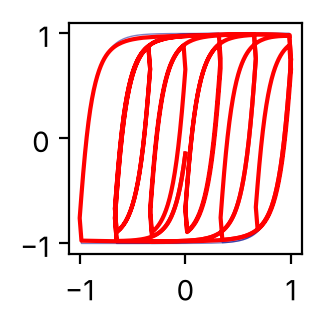

4701  --  0.0020561612
4702  --  0.0020716616
4703  --  0.002085592
4704  --  0.0020975063
4705  --  0.0021068938
4706  --  0.00211331
4707  --  0.002116351


4708  --  0.0021157125
4709  --  0.0021112715
4710  --  0.002103193


4711  --  0.0020919044
4712  --  0.0020779984
4713  --  0.0020621219
4714  --  0.0020449585
4715  --  0.0020274073
4716  --  0.0020102423
4717  --  0.0019940853


4718  --  0.001979453
4719  --  0.0019667158
4720  --  0.0019559825
4721  --  0.001947255


4722  --  0.0019403957
4723  --  0.0019351966
4724  --  0.0019313535
4725  --  0.0019285383
4726  --  0.0019264333
4727  --  0.0019247923
4728  --  0.0019234351


4729  --  0.001922187
4730  --  0.0019210215
4731  --  0.0019199043
4732  --  0.0019189349


4733  --  0.0019182755
4734  --  0.0019181323
4735  --  0.0019187512
4736  --  0.0019203904
4737  --  0.0019232793
4738  --  0.0019276877
4739  --  0.0019338416


4740  --  0.001941915
4741  --  0.0019520913
4742  --  0.0019644964


4743  --  0.0019791536
4744  --  0.00199607
4745  --  0.002015082
4746  --  0.0020358511
4747  --  0.0020577884
4748  --  0.0020799823
4749  --  0.0021011443
4750  --  0.0021197102


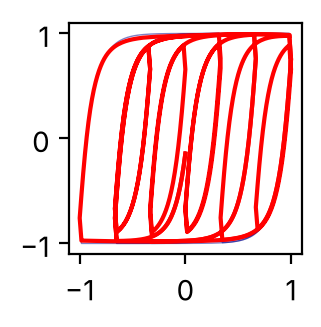

4751  --  0.0021339091
4752  --  0.0021418352
4753  --  0.0021420561
4754  --  0.0021336973
4755  --  0.0021167248
4756  --  0.0020921153
4757  --  0.002061822
4758  --  0.0020284643
4759  --  0.0019952583
4760  --  0.0019648941


4761  --  0.0019419012
4762  --  0.0019305928
4763  --  0.001935926
4764  --  0.0019642652
4765  --  0.0020233903
4766  --  0.0021225605
4767  --  0.0022699954
4768  --  0.0024677864
4769  --  0.0027022387
4770  --  0.002933522
4771  --  0.0030974161
4772  --  0.0031305007
4773  --  0.0030111212


4774  --  0.0027796712
4775  --  0.0025138443
4776  --  0.0022827976
4777  --  0.0021212061
4778  --  0.0020307126
4779  --  0.0019947328
4780  --  0.001990599
4781  --  0.0019975295
4782  --  0.0020004855
4783  --  0.0019926287
4784  --  0.001973288
4785  --  0.0019471546


4786  --  0.0019205706
4787  --  0.0018990037
4788  --  0.0018857922
4789  --  0.0018827342
4790  --  0.0018900987
4791  --  0.0019064503
4792  --  0.0019284349
4793  --  0.0019509696
4794  --  0.0019682683
4795  --  0.0019760893
4796  --  0.0019714714
4797  --  0.0019559371
4798  --  0.001933842


4799  --  0.0019100404
4800  --  0.0018886282


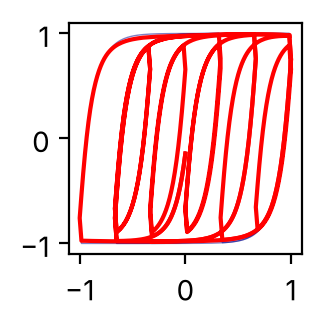

4801  --  0.001872691
4802  --  0.0018629755
4803  --  0.0018587295
4804  --  0.0018583725
4805  --  0.0018599521
4806  --  0.0018615505
4807  --  0.0018617911


4808  --  0.0018599936
4809  --  0.0018563586
4810  --  0.0018516436
4811  --  0.0018471272
4812  --  0.0018442549
4813  --  0.0018443558


4814  --  0.0018484393
4815  --  0.001857046
4816  --  0.0018701995
4817  --  0.0018873144
4818  --  0.0019073157
4819  --  0.0019286849
4820  --  0.0019496818


4821  --  0.0019688776
4822  --  0.0019850906
4823  --  0.0019975088
4824  --  0.0020057228
4825  --  0.002009666


4826  --  0.002009452
4827  --  0.0020055077
4828  --  0.001998369
4829  --  0.0019886547
4830  --  0.0019768765
4831  --  0.0019635768
4832  --  0.001949143
4833  --  0.0019340458


4834  --  0.0019186233
4835  --  0.0019033087
4836  --  0.0018885338
4837  --  0.0018748079


4838  --  0.0018626925
4839  --  0.0018526297
4840  --  0.0018449646
4841  --  0.0018399212
4842  --  0.001837527
4843  --  0.0018376068
4844  --  0.0018397733
4845  --  0.001843423


4846  --  0.0018479221
4847  --  0.0018523305
4848  --  0.0018558658
4849  --  0.0018578676


4850  --  0.0018579342


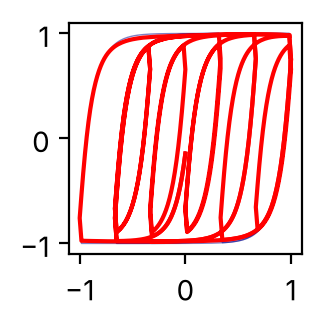

4851  --  0.0018559623
4852  --  0.0018521397
4853  --  0.0018469006


4854  --  0.0018408498
4855  --  0.0018346955
4856  --  0.001829005
4857  --  0.0018241939


4858  --  0.0018204274
4859  --  0.0018177358
4860  --  0.0018159925


4861  --  0.0018149209
4862  --  0.0018142511
4863  --  0.0018138192
4864  --  0.0018135548


4865  --  0.0018136628
4866  --  0.0018146319
4867  --  0.0018172845
4868  --  0.0018228992


4869  --  0.0018332674
4870  --  0.001850811


... (6 outputs left out)

4890  --  0.0019859495
4891  --  0.001993628


4892  --  0.0019866873
4893  --  0.001970796
4894  --  0.0019536125
4895  --  0.0019413497
4896  --  0.0019372168
4897  --  0.001942011


4898  --  0.0019544568
4899  --  0.0019711184


4900  --  0.0019866587


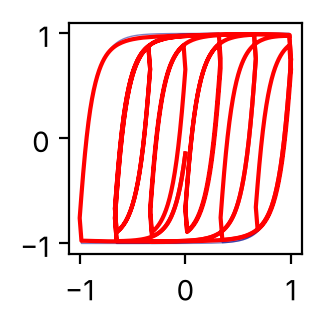

4901  --  0.0019942988
4902  --  0.0019867616
4903  --  0.0019623465
4904  --  0.001925476


4905  --  0.0018831608
4906  --  0.0018430172


4907  --  0.0018110207
4908  --  0.0017889489
4909  --  0.0017756881


4910  --  0.001769304
4911  --  0.0017672372
4912  --  0.0017671646
4913  --  0.0017673452
4914  --  0.0017668525


4915  --  0.0017655364
4916  --  0.0017639239


4917  --  0.0017628643
4918  --  0.001763467
4919  --  0.0017667962
4920  --  0.0017736984


... (5 outputs left out)

4939  --  0.0018563535
4940  --  0.001831463
4941  --  0.0018092335
4942  --  0.0017900864
4943  --  0.001774195


4944  --  0.0017615994
4945  --  0.0017521966
4946  --  0.001745906
4947  --  0.0017425811


4948  --  0.0017420328
4949  --  0.0017440035


4950  --  0.0017482233


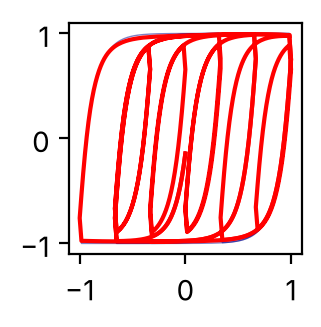

4951  --  0.0017542882
4952  --  0.0017617602
4953  --  0.001770151


4954  --  0.0017789722
4955  --  0.0017877704
4956  --  0.0017961838


4957  --  0.0018039587
4958  --  0.0018109871
4959  --  0.0018172853
4960  --  0.0018229639


4961  --  0.0018281408
4962  --  0.0018328949
4963  --  0.001837183


4964  --  0.0018407939
4965  --  0.0018434189


4966  --  0.0018446331
4967  --  0.0018437725
4968  --  0.0018405748
4969  --  0.0018347627


... (5 outputs left out)

4986  --  0.0025269487
4987  --  0.0026755875
4988  --  0.0027450398
4989  --  0.002704659
4990  --  0.0025623983


4991  --  0.0023626427
4992  --  0.0021610537
4993  --  0.0019982315


4994  --  0.0018892881
4995  --  0.0018288392
4996  --  0.0018020828


4997  --  0.0017927383
4998  --  0.0017884406
4999  --  0.0017820321
5000  --  0.001771877


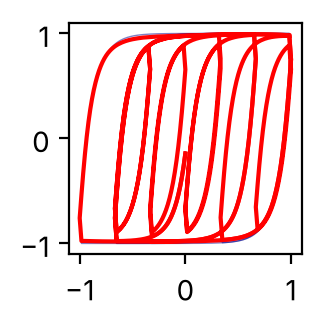

In [11]:
learningRate = 1.e-4
optimizer = optim.NAdam(TANNnet.parameters(),
                        lr=learningRate)
loss_hist = []
loss_fn = torch.nn.MSELoss()

for itr in range(1, niters + 1):
    if itr % test_freq==0:
        fig, ax = plt.subplots(figsize=(1.5,1.5))
    loss_value = 0.
    loss=0.
    for i in range(ntrain):
        
        # Make predictions and backpropagate loss for each path
        
        pred = TANNnet.forward(input_tv[i,:,0])
        
        # loss on evolution equation
        loss = loss_fn(pred[:,0],output_tv[i,:,0,0])
        # loss on energy
        loss += loss_fn(pred[:,1],output_tv[i,:,0,1])
        # loss on stress
        loss += loss_fn(pred[:,2],output_tv[i,:,0,2])
        # loss on dissipation rate
        loss += loss_fn(pred[:,3],output_tv[i,:,0,3])

        loss.backward()
        optimizer.step() 
        optimizer.zero_grad()
        
        loss_value+=loss.item() 
        
        if itr % test_freq==0:
            # Plot stress target values and predictions
            ax.plot(strain_t_tv[i,:,0],output_tv[i,:,0,2].cpu().numpy(),color='darkblue',alpha=0.5,linestyle='-',linewidth=0.5)
            ax.plot(strain_t_tv[i,:,0],pred.detach()[:,2].cpu().numpy(),color='red')
    
    loss_hist.append(loss_value)
    print(itr,' -- ',np.float32(loss_value))
        
    if itr % test_freq==0:
        plt.show()

#### Plot loss history

[]

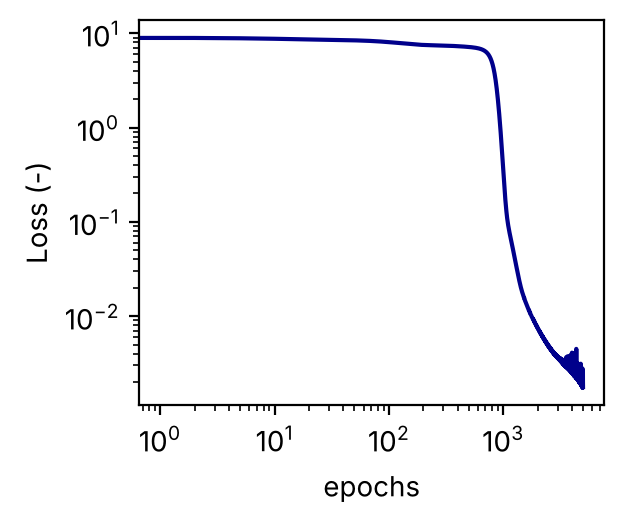

In [12]:
fig, ax = plt.subplots(figsize=(3.,2.5))
ax.loglog(loss_hist,color='darkblue')
ax.set_xlabel('epochs')
ax.set_ylabel('Loss (-)')
plt.plot()

### Model at inference (test set)

In [13]:
# Make predictions for test data
for i in range(ntest):        
    if i == 0:
        pred_test = TANNnet.forward(input_test[i,:,0])
        pred_test = pred_test[None,:,:]
    else:
        pred_test_i = TANNnet.forward(input_test[i,:,0])
        pred_test = torch.cat((pred_test,pred_test_i[None,:,:]),0)
        
pred_test = pred_test.cpu().detach()

<>:8: SyntaxWarning: invalid escape sequence '\d'
<>:9: SyntaxWarning: invalid escape sequence '\d'
<>:8: SyntaxWarning: invalid escape sequence '\d'
<>:9: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_526/1870476901.py:8: SyntaxWarning: invalid escape sequence '\d'
  ax.set_ylabel('$\dot{\\varepsilon}_{pl}$')
/tmp/ipykernel_526/1870476901.py:9: SyntaxWarning: invalid escape sequence '\d'
  ax.set_xlabel('$\dot{\\varepsilon}$')


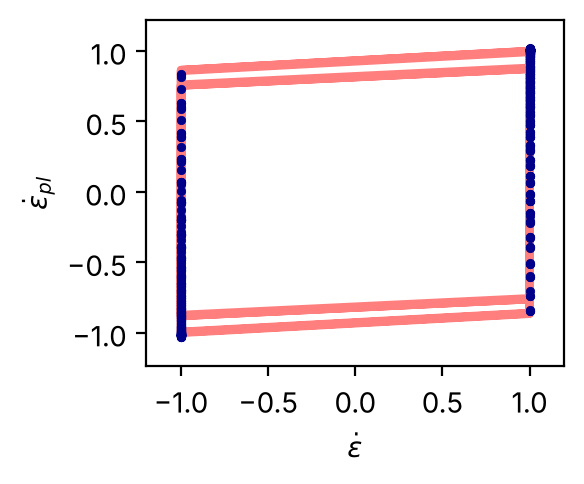

In [14]:
fig, ax = plt.subplots(figsize=(3.,2.5))
ax.margins(x=0.1, y = 0.1)
for i in np.arange(1):
    ax.plot(dstrain_test[i,:,:,0],dstrain_pl_test[i,:,0,0],color='red',
            alpha=0.5,linewidth=3,label='ref')
    ax.plot(dstrain_test[i,:,0],pred_test[i,:,0],alpha=1,linewidth=0,markersize=3,color='darkblue',
            marker='o',label='pred',markeredgewidth=0.3, linestyle='-')
ax.set_ylabel('$\dot{\\varepsilon}_{pl}$')
ax.set_xlabel('$\dot{\\varepsilon}$')
plt.tight_layout(pad=1, w_pad=1.5, h_pad=1.5)
plt.show()

<>:8: SyntaxWarning: invalid escape sequence '\p'
<>:8: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_526/3239214164.py:8: SyntaxWarning: invalid escape sequence '\p'
  ax.set_ylabel('$\psi$')


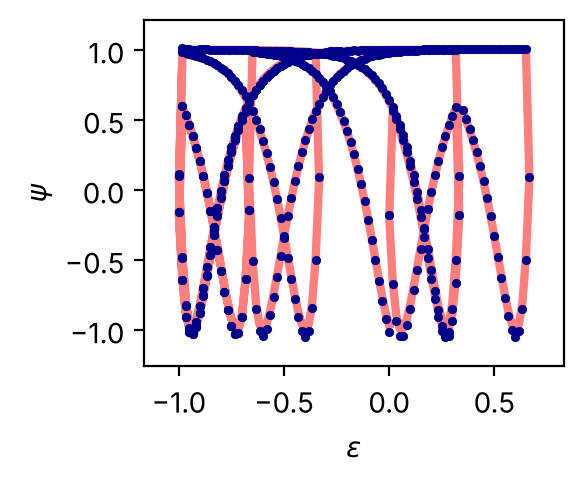

In [15]:
fig, ax = plt.subplots(figsize=(3.,2.5))
ax.margins(x=0.1, y = 0.1)
for i in np.arange(1):
    ax.plot(strain_t_test[i,:,:,0],energy_tdt_test[i,:,0,0],color='red',
            alpha=0.5,linewidth=3,label='ref')
    ax.plot(strain_t_test[i,:,0],pred_test[i,:,1],alpha=1,linewidth=0,markersize=3,color='darkblue',
            marker='o',label='pred',markeredgewidth=0.3, linestyle='-')
ax.set_ylabel('$\psi$')
ax.set_xlabel('$\\varepsilon$')
plt.tight_layout(pad=1, w_pad=1.5, h_pad=1.5)
plt.show()

<>:8: SyntaxWarning: invalid escape sequence '\s'
<>:8: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_526/1727837711.py:8: SyntaxWarning: invalid escape sequence '\s'
  ax.set_ylabel('$\sigma$')


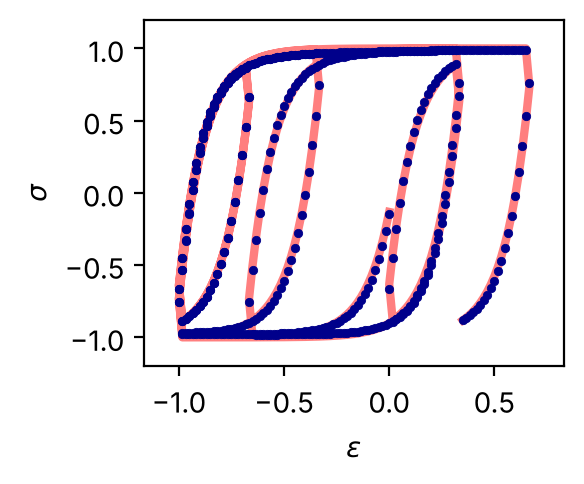

In [16]:
fig, ax = plt.subplots(figsize=(3.,2.5))
ax.margins(x=0.1, y = 0.1)
for i in np.arange(1):
    ax.plot(strain_t_test[i,:,:,0],stress_tdt_test[i,:,0,0],color='red',
            alpha=0.5,linewidth=3,label='ref')
    ax.plot(strain_t_test[i,:,0],pred_test[i,:,2],alpha=1,linewidth=0,markersize=3,color='darkblue',
            marker='o',label='pred',markeredgewidth=0.3, linestyle='-')
ax.set_ylabel('$\sigma$')
ax.set_xlabel('$\\varepsilon$')
plt.tight_layout(pad=1, w_pad=1.5, h_pad=1.5)
plt.show()

<>:9: SyntaxWarning: invalid escape sequence '\d'
<>:9: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_526/937606627.py:9: SyntaxWarning: invalid escape sequence '\d'
  ax.set_xlabel('$\dot{\\varepsilon}_{pl}$')


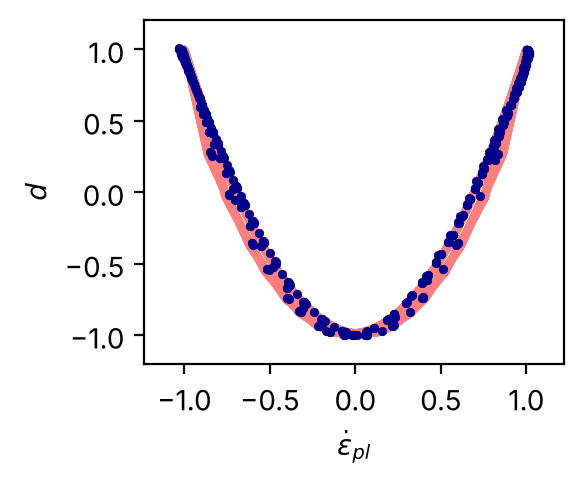

In [17]:
fig, ax = plt.subplots(figsize=(3.,2.5))
ax.margins(x=0.1, y = 0.1)
for i in np.arange(1):
    ax.plot(dstrain_pl_test[i,:,0,0],dissipation_rate_tdt_test[i,:,0,0],color='red',
            alpha=0.5,linewidth=3,label='ref')
    ax.plot(pred_test[i,:,0],pred_test[i,:,3],alpha=1,linewidth=0,markersize=3,color='darkblue',
            marker='o',label='pred',markeredgewidth=0.3, linestyle='-')
ax.set_ylabel('$d$')
ax.set_xlabel('$\dot{\\varepsilon}_{pl}$')
plt.tight_layout(pad=1, w_pad=1.5, h_pad=1.5)
plt.show()